# 02 — Observation-matched initial conditions (`obs`)

No model restarts exist for 2026, so the ELM (land), MOSART (river), and MPAS-Seaice initial conditions come
from one year of the BruteForce archive, used unchanged (averaging restarts would break the consistency of snow
layers, ice categories, and phenology). This workflow selects the year whose anomaly is **closest to the
observed anomaly on the target date**, writes its restarts, and evaluates them against the JRA55-FOSIRL 2015
restarts to `OUT_ROOT/YYYYMMDD/<comp>/obs/`. `OBS_SET` chooses the observations: `era5land_nsidc` (default; ERA5-Land
for land, NOAA/NSIDC CDR for sea-ice concentration) or `era5` (ERA5 for both); the set used is recorded in
`selection.json` and `config.json`.


| Notebook | Workflow | Method (`OUT_ROOT/YYYYMMDD/<comp>/<method>/`) |
| --- | --- | --- |
| `01_clim_match_ic.ipynb` | climatology-match | `clim` |
| `02_obs_match_ic.ipynb` | observation-match | `obs` (observations chosen by `OBS_SET`) |
| `03_hybrid_ic.ipynb` | climatology + observed anomaly | `hybrid_ic` |
| `04_compare_ic_methods.ipynb` | comparison of the methods | reads the outputs saved by 01-03 |

Each of 01-03 is self-contained: read the data, choose the box size, select or build the initial
conditions, write the restarts, evaluate them against JRA55-FOSIRL 2015, draw the native-mesh maps, and save the
outputs for 04.

Contents: 1. read the input data; 2. choose the box size; 3. distances and selection; 4. write the restarts;
5. evaluation against JRA55-FOSIRL 2015; 6. native-mesh maps; 7. save the outputs; 8. key findings.

Code: `util/clim_restart.py` (key fields, distances, selection, writing), `util/ic_eval.py` (evaluation and
maps), `util/ic_store.py` (saved outputs). The BruteForce archive and the observations are only read.

In [1]:
from pathlib import Path
import importlib
import sys
import warnings

import IPython.display as ipd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("util").resolve()))     # run from this directory
import anom_restart
import box_loo
import clim_restart as cr
import ic_eval as ice
import ic_store

# Reload so edits to util/ take effect without restarting the kernel.
for module in (cr, box_loo, anom_restart, ice, ic_store):
    importlib.reload(module)

ice.ensure_proj_data()
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 80     # inline figures; saved figures use FIG_DPI
quiet = lambda *args: None

## Method

For each observable key field $f$, model values of each archive year and the observed values of the same
years are converted to standardized anomalies with their own climatological mean and spread over the
**climatology years** (`CLIM_FIRST_YEAR`-`CLIM_LAST_YEAR`; by default the candidate years). The distance of a
candidate year from the observed anomaly on the target date $T$ is

$$d_f(y)=\sqrt{\frac{\sum_i w_i\,(z_{y,i}-t_i)^2}{\sum_i w_i}},\qquad t_i=\frac{o_{T,i}-\bar o_i}{S_\mathrm{obs}}$$

on `BOX` lat-lon boxes (model and observations averaged over the same points). Comparing anomalies cancels
model-observation biases and unit or layer-depth differences; only fields with an observed counterpart are used
(sea-ice concentration per hemisphere; snow water equivalent, surface and subsurface soil water and soil
temperature). Component and joint distances and `MODE` are as in `01_clim_match_ic.ipynb`; the river always takes
the land year. Dates whose observations are not on disk yet are skipped.

## Configuration

Every option of the workflow is set here; the sections below only use these names.

In [2]:
# ---- Archive and output locations ----------------------------------------------------------
SRC_ROOT   = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")   # BruteForce restarts, read-only
SRC_PREFIX = "20251024_s2d_spinup"
IC_SOURCE  = "JRA55-FOSIRL"            # source of the archive land, river, and sea-ice restarts (figure labels)
OUT_ROOT   = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")
OUT_PREFIX = "20251024_s2d_spinup"     # matches my_refcase2 in the hindcast driver
CACHE_DIR  = OUT_ROOT / "cache"        # model and observed key fields, shared by 01-04
DIAG_ROOT  = Path("/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic")
OBS_DATA   = Path("/global/cfs/cdirs/e3sm/zhan391/data")
ERA5_DIR   = Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc")

# Observation sets: per-component root and observed fields (ERA5 names; the data format,
# ERA5 0.25 deg, ERA5-Land 1x1, or NOAA/NSIDC 1x1, is recognized from the root layout).
OBS_SETS = {
    "era5land_nsidc": {       # default: ERA5-Land for land, NOAA/NSIDC sea-ice concentration CDR
        "label": "ERA5-Land/NSIDC",
        "root": {"elm": OBS_DATA / "ERA5_LND", "mpassi": OBS_DATA / "NOAA_NSIDC"},
        "fields": {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]},
    },
    "era5": {                 # ERA5 for land and sea ice
        "label": "ERA5",
        "root": {"elm": ERA5_DIR, "mpassi": ERA5_DIR},
        "fields": {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]},
    },
}

OBS_SET = "era5land_nsidc"      # observations used for the selection (a key of OBS_SETS)
METHOD  = "obs"                 # writes OUT_ROOT/YYYYMMDD/<comp>/obs/ and DIAG_ROOT/obs/ for any OBS_SET

EVAL_OBS = OBS_SETS[OBS_SET]    # the evaluation compares with the same observations

# ---- Dates and components ------------------------------------------------------------------
TEST_DATES     = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]   # scored against JRA55-FOSIRL 2015
HINDCAST_DATES = ["2026-02-01", "2026-05-01", "2026-08-01", "2026-11-01"]
TARGET_DATES   = TEST_DATES + HINDCAST_DATES
COMPONENTS     = ["elm", "mosart", "mpassi"]   # the river (mosart) always follows the land year

# ---- Years ---------------------------------------------------------------------------------
SEARCH_FIRST_YEAR   = 1995    # candidate years searched; None: first archive year (1980)
SEARCH_LAST_YEAR    = None    # None: last archive year (2018)
EXCLUDE_YEARS       = []      # never selected
CLIM_FIRST_YEAR     = None    # climatology: mean and interannual spread of every model and observed
CLIM_LAST_YEAR      = None    #   field; None and None use the candidate years
EXCLUDE_TARGET_YEAR = True    # leave the target year out of both (2015 cannot select itself)

# ---- Distance and selection ----------------------------------------------------------------
BOX_CHOICE    = "loo"         # "loo": chosen by the leave-one-out test (section 2); or (dlat, dlon); None: model points
LOO_BOXES     = [None, (10, 20), (15, 30), (20, 40), (30, 60), (45, 90)]   # box sizes tested (None: model points)
LOO_SCORES    = {"points": None, "30x60": (30, 60)}   # primary: closeness at model points; tie-breaker: 30x60 means
LOO_OBS       = OBS_SET   # observations of the test (a key of OBS_SETS)
LOO_RECOMPUTE = False         # True reruns the test (about 12 min, one process per month); else reuse a saved one
BOX_SHIFTS    = 4             # placements of the box edges averaged in the distance (1, 2, or 4)
MODE       = "joint"          # "joint": one year for all components; "per_component": each its own
COMPONENT_WEIGHTS = {"elm": 1.0, "mpassi": 1.0}   # weights a_c in the joint distance

# ---- Evaluation ----------------------------------------------------------------------------
EVAL_DATES   = TEST_DATES     # dates whose actual restarts the initial conditions are compared with
EXAMPLE_DATE = "2015-02-01"   # date of the single-date maps
MAP_DATES    = EVAL_DATES     # dates of the per-date ELM maps

# ---- Output --------------------------------------------------------------------------------
WRITE_OUTPUT = True           # write the restarts to OUT_ROOT/YYYYMMDD/<comp>/<METHOD>/
OVERWRITE    = True           # replace restarts written before
SAVE_DIAG    = True           # figures to DIAG/figure; tables, states, and settings to DIAG/data
FIG_DPI      = 150
DIAG = DIAG_ROOT / METHOD
ice.IC_SOURCE = IC_SOURCE     # labels every archive state in the figures and tables

## 1. Read the input data

One plan per target date with observations on disk: candidate years (all three restarts available on the
calendar date, target year excluded), climatology years, and output directory. The model key fields of every
year read and the observed fields (one 00Z / daily slice per variable and year) are cached under `CACHE_DIR`.
The table gives, for `EXAMPLE_DATE`, the points read, the area-weighted climatological mean, and the
interannual spread `S` over the climatology years, for the model and the observations.

In [3]:
def years_table(plans):
    """Candidate and climatology years of each plan."""
    span = lambda years: f"{years[0]}-{years[-1]} ({len(years)})"
    return pd.DataFrame({date: {"candidate years": span(p.candidate_years), "climatology years": span(p.clim_years),
                                "excluded": p.excluded_years, "output": {c: str(p.method_dir(c)) for c in (*p.components, "cpl")}}
                         for date, p in plans.items()}).T

common = dict(src_root=SRC_ROOT, out_root=OUT_ROOT, src_prefix=SRC_PREFIX, out_prefix=OUT_PREFIX,
              components=COMPONENTS, first_year=SEARCH_FIRST_YEAR, last_year=SEARCH_LAST_YEAR,
              clim_first_year=CLIM_FIRST_YEAR, clim_last_year=CLIM_LAST_YEAR,
              exclude_years=EXCLUDE_YEARS, exclude_target_year=EXCLUDE_TARGET_YEAR)
plans = {}
for date in TARGET_DATES:
    if not cr.era5_available(date, obs_root=EVAL_OBS["root"], obs_fields=EVAL_OBS["fields"], components=COMPONENTS):
        print(f"skip {date}: {EVAL_OBS['label']} not available yet")
        continue
    plans[date] = cr.make_plan(date, "obs", label=METHOD, obs_root=EVAL_OBS["root"], obs_fields=EVAL_OBS["fields"],
                               **common)
ipd.display(years_table(plans))

inputs = pd.concat([cr.input_summary(plan, CACHE_DIR, log=quiet) for plan in plans.values()], ignore_index=True)
ipd.display(inputs[inputs["target_date"] == EXAMPLE_DATE].drop(columns="target_date").round(3))

,candidate years,climatology years,excluded,output
2015-02-01,1995-2018 (23),1995-2018 (23),[2015],{'elm': '/global/cfs/cdirs/e3sm/S2S2D/RTENSO20...
2015-05-01,1995-2018 (23),1995-2018 (23),[2015],{'elm': '/global/cfs/cdirs/e3sm/S2S2D/RTENSO20...
2015-08-01,1995-2018 (23),1995-2018 (23),[2015],{'elm': '/global/cfs/cdirs/e3sm/S2S2D/RTENSO20...
2015-11-01,1995-2018 (23),1995-2018 (23),[2015],{'elm': '/global/cfs/cdirs/e3sm/S2S2D/RTENSO20...
2026-02-01,1995-2018 (24),1995-2018 (24),[2026],{'elm': '/global/cfs/cdirs/e3sm/S2S2D/RTENSO20...
2026-05-01,1995-2018 (24),1995-2018 (24),[2026],{'elm': '/global/cfs/cdirs/e3sm/S2S2D/RTENSO20...
2026-08-01,1995-2018 (24),1995-2018 (24),[2026],{'elm': '/global/cfs/cdirs/e3sm/S2S2D/RTENSO20...
2026-11-01,1995-2018 (24),1995-2018 (24),[2026],{'elm': '/global/cfs/cdirs/e3sm/S2S2D/RTENSO20...


,component,field,source,variable,years read,points,clim mean,spread S
0,elm,snow water equivalent,model,restart,1995-2018 (23),238725,130.595,26.128
1,elm,snow water equivalent,observed,sd,1995-2018 (23),86727,1.143,0.047
2,elm,surface soil water,model,restart,1995-2018 (23),238725,32.268,4.027
3,elm,surface soil water,observed,swvl1,1995-2018 (23),86727,0.261,0.041
4,elm,subsurface soil water,model,restart,1995-2018 (23),165408,4992.349,35.042
5,elm,subsurface soil water,observed,swvl2-4,1995-2018 (23),86727,0.755,0.050
6,elm,surface soil temperature,model,restart,1995-2018 (23),238725,280.718,2.458
7,elm,surface soil temperature,observed,stl1,1995-2018 (23),86727,278.935,2.251
8,elm,subsurface soil temperature,model,restart,1995-2018 (23),165408,284.179,0.949
9,elm,subsurface soil temperature,observed,stl2-4,1995-2018 (23),86727,282.451,0.851


## 2. Choose the box size

Distances compare area-weighted means over lat-lon boxes of `BOX = (dlat, dlon)` degrees, averaged over
`BOX_SHIFTS` placements of the box edges (standard, and shifted by half a box in latitude, in longitude, and in
both, so the result does not hinge on where the edges fall). The box is chosen by a leave-one-out test on the
archive alone, so the 2015 test dates stay independent of it:

1. For each calendar month of `TARGET_DATES` and each archive year $y$ (`SEARCH_FIRST_YEAR`-`SEARCH_LAST_YEAR`),
   treat $y$ as the unknown target. The observation-matched selection with box $b$ picks, from the other years,
   the year closest to the observed anomaly of $y$ (`LOO_OBS`).
2. Score the pick against the **JRA55-FOSIRL state of $y$** (the model state the selection should find): joint distance over the observable fields or all
   key fields (including sea-ice thickness and snow on ice, which have no observations).

Skill of a pick: $(D_\mathrm{rms}-D_\mathrm{pick})/(D_\mathrm{rms}-D_\mathrm{best})$, with $D_\mathrm{best}$ the
closest candidate (skill 1) and $D_\mathrm{rms}$ the RMS over the candidates (a random pick, skill about 0).

**Decision rule.** The primary criterion is closeness on the native model grid: boxes whose skill at model
points is within two standard errors (paired by held-out year) of the best are tied. Among them, the one with
the highest large-scale skill (both states averaged over 30x60 boxes) is chosen. Every box is judged at these
same two scales. The test uses the candidate years as its climatology.

The result is saved under `DIAG_ROOT/data/` with a name that records the observations, years, and box shifts,
and reused while those settings are unchanged (`LOO_RECOMPUTE = True` reruns it). Set `BOX_CHOICE` to a
`(dlat, dlon)` pair, or `None` for model points, to override the choice. Code: `util/box_loo.py`.

In [4]:
LOO_MONTHS = sorted({d[5:] for d in TARGET_DATES})
LOO_TAG = f"{LOO_OBS}_{SEARCH_FIRST_YEAR or 'start'}-{SEARCH_LAST_YEAR or 'end'}_shift{BOX_SHIFTS}"
LOO_CSV = DIAG_ROOT / "data" / f"box_size_loo_{LOO_TAG}.csv"
LABELS = [box_loo.box_label(b) for b in LOO_BOXES]

loo = box_loo.add_skill(pd.read_csv(LOO_CSV, dtype={"month": str})) if LOO_CSV.is_file() else None
if (LOO_RECOMPUTE or loo is None or not set(LABELS) <= set(loo["box"])
        or not set(LOO_MONTHS) <= set(loo["month"])):
    loo = box_loo.run_loo(LOO_MONTHS, src_root=SRC_ROOT, out_root=OUT_ROOT, cache_dir=CACHE_DIR,
                          first_year=SEARCH_FIRST_YEAR, last_year=SEARCH_LAST_YEAR, boxes=LOO_BOXES,
                          scores=LOO_SCORES, box_shifts=BOX_SHIFTS,
                          obs_root=OBS_SETS[LOO_OBS]["root"], obs_fields=OBS_SETS[LOO_OBS]["fields"])
    LOO_CSV.parent.mkdir(parents=True, exist_ok=True)
    loo.to_csv(LOO_CSV, index=False)
    print(f"saved {LOO_CSV}")
else:
    print(f"read {LOO_CSV}")
loo = loo[loo["box"].isin(LABELS) & loo["month"].isin(LOO_MONTHS)]
print(f"{len(loo)} rows; test years per month: {dict(loo.groupby('month')['year'].nunique())}")

# Mean skill (0 = random year, 1 = best possible year) by box and month, for each scoring scale and field set.
for key in box_loo.score_keys(loo):
    print(f"scored at {key}")
    ipd.display(box_loo.skill_table(loo, key, LABELS).style.format("{:.3f}").highlight_max(axis=0, color="#cde"))

read /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/data/box_size_loo_era5land_nsidc_1995-end_shift4.csv
576 rows; test years per month: {'02-01': np.int64(24), '05-01': np.int64(24), '08-01': np.int64(24), '11-01': np.int64(24)}
scored at points,observable


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.759,0.842,0.751,0.839,0.798
10x20,0.770,0.812,0.797,0.826,0.801
15x30,0.760,0.750,0.793,0.817,0.780
20x40,0.715,0.750,0.763,0.829,0.764
30x60,0.645,0.730,0.670,0.792,0.709
45x90,0.612,0.721,0.607,0.737,0.669


scored at points,all


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.708,0.714,0.589,0.696,0.677
10x20,0.695,0.737,0.677,0.750,0.715
15x30,0.679,0.670,0.655,0.760,0.691
20x40,0.675,0.663,0.650,0.791,0.695
30x60,0.468,0.603,0.524,0.747,0.586
45x90,0.493,0.652,0.603,0.784,0.633


scored at 30x60,observable


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.749,0.729,0.787,0.834,0.775
10x20,0.763,0.755,0.734,0.836,0.772
15x30,0.787,0.825,0.731,0.837,0.795
20x40,0.717,0.858,0.780,0.847,0.800
30x60,0.743,0.888,0.748,0.821,0.800
45x90,0.703,0.834,0.742,0.813,0.773


scored at 30x60,all


month,02-01,05-01,08-01,11-01,all
box,,,,,
points,0.675,0.675,0.582,0.676,0.652
10x20,0.678,0.707,0.575,0.743,0.676
15x30,0.732,0.694,0.576,0.758,0.690
20x40,0.643,0.707,0.556,0.785,0.673
30x60,0.574,0.725,0.478,0.747,0.631
45x90,0.592,0.729,0.603,0.786,0.678


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/box_size_loo_skill_era5land_nsidc_1995-end_shift4.png


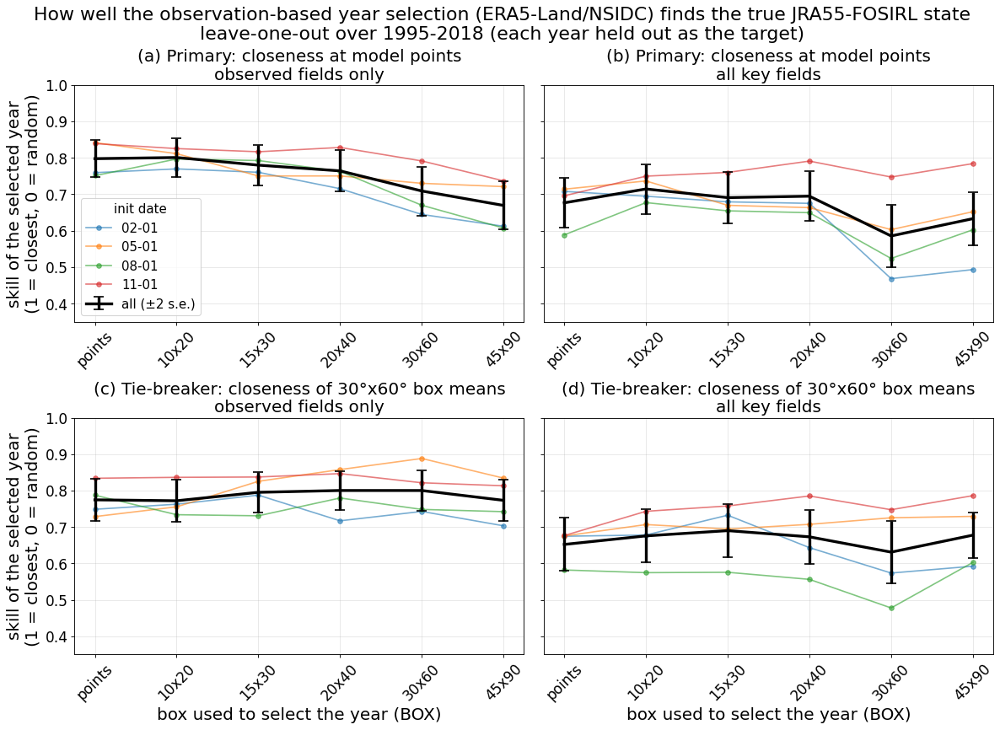

In [5]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE    = 18              # base font size; other text scales from it
PANEL_SIZE  = (7.5, 5.5)      # width, height of one panel (inches)
LINE_WIDTH  = 1.5             # per-month lines (the all-month line is 2x)
MARKER_SIZE = 5
YLIM        = (0.35, 1.0)     # None for automatic
LEGEND_LOC  = "lower left"    # legend placed in panel (a)
ROW_TITLES  = {"points": "Primary: closeness at model points",
               "30x60": "Tie-breaker: closeness of 30°x60° box means"}
COL_TITLES  = {"observable": "observed fields only", "all": "all key fields"}
# ---------------------------------------------------------------------------------------------
fs = {"title": FONTSIZE, "label": FONTSIZE, "tick": 0.85 * FONTSIZE,
      "legend": 0.75 * FONTSIZE, "suptitle": 1.1 * FONTSIZE}
rows_, cols_ = list(LOO_SCORES), list(box_loo.FIELD_SETS)
fig, axes = plt.subplots(len(rows_), len(cols_),
                         figsize=(PANEL_SIZE[0] * len(cols_), PANEL_SIZE[1] * len(rows_)),
                         sharey=True, squeeze=False)
x = np.arange(len(LABELS))
for r, scale in enumerate(rows_):
    for c, fset in enumerate(cols_):
        ax, key = axes[r, c], f"{scale},{fset}"
        table = box_loo.skill_table(loo, key, LABELS)
        for month in LOO_MONTHS:
            ax.plot(x, table[month], "o-", lw=LINE_WIDTH, ms=MARKER_SIZE, alpha=0.6, label=month)
        per_year = loo.pivot_table(index=["month", "year"], columns="box", values=f"skill[{key}]")[LABELS]
        se = per_year.std() / np.sqrt(len(per_year))
        ax.errorbar(x, table["all"], yerr=2 * se, color="k", lw=2 * LINE_WIDTH, ms=MARKER_SIZE,
                    capsize=0.3 * FONTSIZE, capthick=LINE_WIDTH, label="all (±2 s.e.)")
        ax.set_xticks(x, LABELS, rotation=45)
        ax.tick_params(labelsize=fs["tick"])
        if YLIM is not None:
            ax.set_ylim(*YLIM)
        ax.set_title(f"({'abcd'[r * len(cols_) + c]}) {ROW_TITLES.get(scale, scale)}\n"
                     f"{COL_TITLES.get(fset, fset)}", fontsize=fs["title"])
        ax.grid(alpha=0.3)
        if r == len(rows_) - 1:
            ax.set_xlabel("box used to select the year (BOX)", fontsize=fs["label"])
        if c == 0:
            ax.set_ylabel("skill of the selected year\n(1 = closest, 0 = random)", fontsize=fs["label"])
axes[0, 0].legend(title="init date", loc=LEGEND_LOC, fontsize=fs["legend"], title_fontsize=fs["legend"])
fig.suptitle(f"How well the observation-based year selection ({OBS_SETS[LOO_OBS]['label']}) finds the true {IC_SOURCE} state\n"
             f"leave-one-out over {loo['year'].min()}-{loo['year'].max()} (each year held out as the target)",
             fontsize=fs["suptitle"])
fig.tight_layout()
ice.save_fig(fig, f"box_size_loo_skill_{LOO_TAG}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

In [6]:
# Primary (native grid): boxes within two standard errors of the best at model points, for both field sets.
# Tie-breaker (large scale): the highest mean skill of the 30x60 box means.
if BOX_CHOICE == "loo":
    chosen, box_choice = box_loo.choose_box(loo, LABELS)
    ipd.display(box_choice.round(3))
    BOX = box_loo.box_from_label(chosen)
else:
    BOX = BOX_CHOICE
print(f"BOX = {BOX}, BOX_SHIFTS = {BOX_SHIFTS}")

,"skill [points,observable]","vs best [points,observable]","skill [points,all]","vs best [points,all]",tied with best on grid,large-scale skill (tie-breaker)
points,0.798,-0.003 ± 0.049,0.677,-0.038 ± 0.058,True,0.713
10x20,0.801,+0.000 ± 0.000,0.715,+0.000 ± 0.000,True,0.724
15x30,0.780,-0.021 ± 0.032,0.691,-0.024 ± 0.045,True,0.743
20x40,0.764,-0.037 ± 0.036,0.695,-0.020 ± 0.052,False,0.737
30x60,0.709,-0.092 ± 0.057,0.586,-0.129 ± 0.079,False,0.716
45x90,0.669,-0.132 ± 0.069,0.633,-0.082 ± 0.083,False,0.725


BOX = (15.0, 30.0), BOX_SHIFTS = 4


## 3. Distances and selection

`best D` is the distance of the selected year; `2nd`/`3rd` are the next closest years and `median D` the
median over the candidates (a typical year).

In [7]:
distances, selections = {}, {}
for date, plan in plans.items():
    distances[date] = cr.compute_distances(plan, box=BOX, box_shifts=BOX_SHIFTS,
                                           component_weights=COMPONENT_WEIGHTS, cache_dir=CACHE_DIR, log=quiet)
    selections[date] = cr.select_years(distances[date], COMPONENTS, MODE)

summary = []
for date, table in distances.items():
    ranked = table["joint"].sort_values()
    row = {"target_date": date, "n_candidates": len(table)}
    row.update({f"{c} year": y for c, y in selections[date].items()})
    row.update({"best D": ranked.iloc[0], "2nd year": ranked.index[1], "2nd D": ranked.iloc[1],
                "3rd year": ranked.index[2], "3rd D": ranked.iloc[2], "median D": ranked.median()})
    summary.append(row)
summary = pd.DataFrame(summary)
ipd.display(summary.round(3))

,target_date,n_candidates,elm year,mosart year,mpassi year,best D,2nd year,2nd D,3rd year,3rd D,median D
0,2015-02-01,23,2014,2014,2014,1.139,2013,1.211,2010,1.218,1.395
1,2015-05-01,23,2014,2014,2014,1.091,2008,1.133,2012,1.163,1.387
2,2015-08-01,23,2017,2017,2017,1.151,2009,1.197,2008,1.212,1.371
3,2015-11-01,23,2014,2014,2014,1.163,2004,1.268,2002,1.282,1.401
4,2026-02-01,24,2010,2010,2010,1.289,2013,1.316,2015,1.434,1.559
5,2026-05-01,24,2011,2011,2011,1.274,2007,1.301,2006,1.327,1.495
6,2026-08-01,24,2016,2016,2016,1.340,2005,1.381,2013,1.427,1.549
7,2026-11-01,24,2015,2015,2015,1.719,2016,1.776,2011,1.806,2.039


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/obs_distance_by_year.png


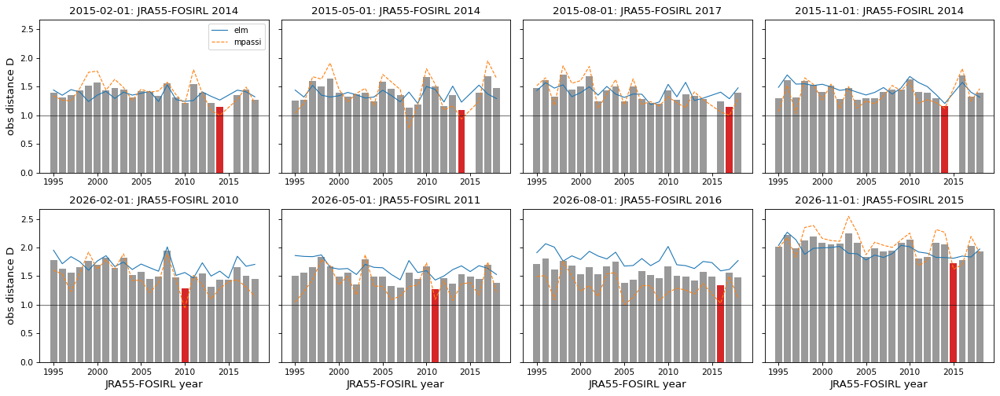

In [8]:
# Joint distance D by candidate year for each date; the selected year is red. Lower is closer.
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE   = 12
PANEL_SIZE = (4.0, 3.2)       # width, height of one panel (inches)
NCOL       = 4
# ---------------------------------------------------------------------------------------------
dates = list(distances)
nrow = -(-len(dates) // NCOL)
fig, axes = plt.subplots(nrow, NCOL, figsize=(PANEL_SIZE[0] * NCOL, PANEL_SIZE[1] * nrow), sharey=True,
                         squeeze=False)
for ax in axes.flat[len(dates):]:
    ax.axis("off")
for ax, date in zip(axes.flat, dates):
    table = distances[date]
    best = int(table["joint"].idxmin())
    years = table.index.to_numpy()
    ax.bar(years, table["joint"], color=["tab:red" if y == best else "0.6" for y in years])
    for comp, style in zip([c for c in COMPONENTS if c in table], ("-", "--", ":")):
        ax.plot(years, table[comp], style, lw=1, label=comp)
    ax.axhline(1, color="k", lw=0.5)
    ax.set_title(f"{date}: {IC_SOURCE} {best}", fontsize=FONTSIZE)
    ax.tick_params(labelsize=0.8 * FONTSIZE)
for ax in axes[:, 0]:
    ax.set_ylabel(f"{METHOD} distance D", fontsize=FONTSIZE)
for ax in axes[-1]:
    ax.set_xlabel(f"{IC_SOURCE} year", fontsize=FONTSIZE)
axes[0, 0].legend(fontsize=0.75 * FONTSIZE)
fig.tight_layout()
ice.save_fig(fig, f"{METHOD}_distance_by_year", DIAG, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

**Figure 3.1.** Distance of each candidate year from the observed anomaly, one panel per target date with
observations on disk (title: the date and the selected JRA55-FOSIRL year; 2026-11-01 is left out until its
observations exist). Bars: the joint distance D over the land (`elm`) and sea-ice (`mpassi`) fields that have
an observed counterpart (ERA5-Land snow water equivalent, soil water, and soil temperature; NOAA/NSIDC CDR
sea-ice concentration per hemisphere), equally weighted; the selected year, the smallest D, is red. Lines: the
component distances D_c of ELM (solid) and MPAS-Seaice (dashed). D is the RMS difference between the
standardized anomalies of the model year and of the observations on the `BOX` boxes, averaged over
`BOX_SHIFTS` placements of the box edges, each anomaly in units of its own interannual spread over the
climatology years (1995-2018, without the target year on the 2015 dates, so the 2015 bar is missing in the top
row). The horizontal line marks D = 1 (one standard deviation). For a year unrelated to the observed anomaly,
D² is about 1 plus the mean square of the observed anomaly, so D stays above 1 for most years. The river
(`mosart`) takes the land year.

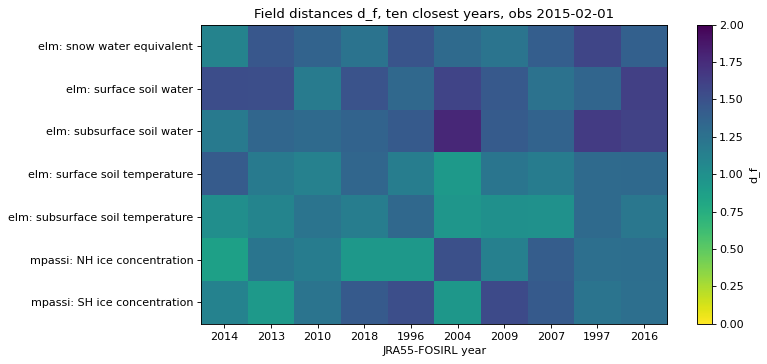

In [9]:
# Field distances d_f of the ten closest years on EXAMPLE_DATE.
table = distances[EXAMPLE_DATE].sort_values("joint").head(10)
fields = [c for c in table.columns if ": " in c]
fig, ax = plt.subplots(figsize=(10, 0.45 * len(fields) + 1.5))
im = ax.imshow(table[fields].T, aspect="auto", cmap="viridis_r", vmin=0, vmax=2)
ax.set_xticks(range(len(table)), table.index)
ax.set_xlabel(f"{IC_SOURCE} year")
ax.set_yticks(range(len(fields)), fields)
ax.set_title(f"Field distances d_f, ten closest years, {METHOD} {EXAMPLE_DATE}")
fig.colorbar(im, ax=ax, label="d_f")
fig.tight_layout()
plt.show()

## 4. Write the restarts

Copies each selected restart (unchanged) to `OUT_ROOT/YYYYMMDD/<comp>/<METHOD>/<prefix>.<stream>.<target date>.nc`,
writes `rpointer.lnd`, `rpointer.rof`, and `rpointer.ice`, and records the plan (candidate and climatology
years), the selection, and the full distance table in `selection.json`. A restart that already holds the
selected year is not copied again. Set `WRITE_OUTPUT = True` to run.

In [10]:
if WRITE_OUTPUT:
    for date, plan in plans.items():
        cr.write_selected_restarts(plan, selections[date], distances[date], mode=MODE, box=BOX,
                                   box_shifts=BOX_SHIFTS, component_weights=COMPONENT_WEIGHTS,
                                   overwrite=OVERWRITE, log=quiet)

rows = []
for date, plan in plans.items():
    for comp in COMPONENTS:
        year = selections[date][comp]
        out, src = plan.output(comp), plan.source(comp, year)
        rows.append({"target_date": date, "component": comp, "year": year, "written": out.is_file(),
                     "same size as source": out.is_file() and out.stat().st_size == src.stat().st_size})
ipd.display(pd.DataFrame(rows).pivot(index="target_date", columns="component",
                                     values=["year", "written", "same size as source"]))

year               written               same size as source              
component     elm mosart mpassi     elm mosart mpassi                 elm mosart mpassi
target_date                                                                            
2015-02-01   2014   2014   2014    True   True   True                True   True   True
2015-05-01   2014   2014   2014    True   True   True                True   True   True
2015-08-01   2017   2017   2017    True   True   True                True   True   True
2015-11-01   2014   2014   2014    True   True   True                True   True   True
2026-02-01   2010   2010   2010    True   True   True                True   True   True
2026-05-01   2011   2011   2011    True   True   True                True   True   True
2026-08-01   2016   2016   2016    True   True   True                True   True   True
2026-11-01   2015   2015   2015    True   True   True                True   True   True

## 5. Evaluation against the JRA55-FOSIRL 2015 IC

The land, river, and sea-ice restarts of the BruteForce archive are the JRA55-FOSIRL restarts, so every model
state here is a JRA55-FOSIRL state (labelled `IC_SOURCE` in the figures): the reference (the 2015 IC), the
candidate years, and the climatology. The 2015 dates are prepared the same way as 2026 (2015 excluded from the
candidate and climatology years), so the JRA55-FOSIRL 2015 IC shows how close the initial condition is to the
true model state.

### 5.1 Is the selected year the candidate closest to JRA55-FOSIRL 2015?

Every candidate year is scored directly against the JRA55-FOSIRL 2015 IC on `BOX` boxes
(`D_true`; rank 1 = closest). The scatter compares the selection distance with `D_true` over all candidates.

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/rank_summary.csv


,target_date,closest to 2015 (obs fields),min D_true (obs fields),closest to 2015 (all fields),min D_true (all fields),obs year,obs: D_true (obs fields),obs: rank (obs fields),obs: rank corr (obs),obs: D_true (all fields),obs: rank (all fields)
0,2015-02-01,2014,1.163,2014,1.271,2014,1.163,1,0.853,1.271,1
1,2015-05-01,2014,0.961,2014,1.093,2014,0.961,1,0.907,1.093,1
2,2015-08-01,2017,1.135,2009,1.151,2017,1.135,1,0.941,1.305,7
3,2015-11-01,2014,1.210,2014,1.222,2014,1.210,1,0.709,1.222,1


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/2015_distance_vs_truth_scatter.png


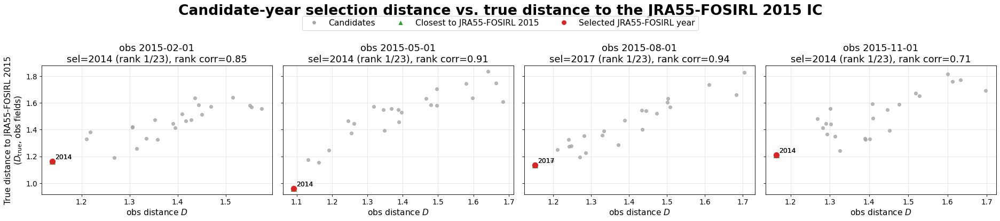

In [11]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14        # panel-title font size; titles, labels, and ticks scale from it
PANEL_SIZE = None    # (width, height) of each panel in inches; None scales with FONTSIZE
# ---------------------------------------------------------------------------------------------
eval_plans = {(METHOD, d): plans[d] for d in EVAL_DATES if d in plans}
eval_distances = {(METHOD, d): distances[d] for d in EVAL_DATES if d in distances}
rank_summary, truth_obs, truth_all = ice.evaluate_distance_ranks(
    EVAL_DATES, eval_plans, eval_distances, box=BOX, component_weights=COMPONENT_WEIGHTS, cache_dir=CACHE_DIR
)
ice.save_table(rank_summary, "rank_summary", DIAG, SAVE_DIAG)
ipd.display(rank_summary.round(3))

fig = ice.plot_distance_vs_truth(EVAL_DATES, eval_distances, truth_obs, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
ice.save_fig(fig, "2015_distance_vs_truth_scatter", DIAG, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

### 5.2 Common score: distance of the initial condition from the observations and from JRA55-FOSIRL 2015

The same score in all three workflows (`ic_store.evaluate_states`, saved as `state_distance.csv`): the joint
distance D (observable fields) of the initial-condition state from the observed standardized anomaly on the
target date, and from the JRA55-FOSIRL 2015 IC (2015 dates), on `BOX` boxes and at model points. Lower is closer;
a typical candidate year has D of about 1.4-1.5 from the observations.

In [12]:
states = {date: ic_store.year_states(plan, selections[date], CACHE_DIR) for date, plan in plans.items()}
state_eval = pd.concat([ic_store.evaluate_states(plans[d], {METHOD: states[d]}, box=BOX, cache_dir=CACHE_DIR)
                        for d in plans], ignore_index=True)
ipd.display(state_eval.pivot_table(index="target_date", columns=["versus", "scale"], values="joint").round(3))

versus      JRA55-FOSIRL 2015        observed       
scale                   15x30 points    15x30 points
target_date                                         
2015-02-01              1.163  1.302    1.108  1.287
2015-05-01              0.961  1.156    1.086  1.307
2015-08-01              1.135  1.299    1.179  1.316
2015-11-01              1.210  1.272    1.163  1.269
2026-02-01                NaN    NaN    1.292  1.361
2026-05-01                NaN    NaN    1.252  1.375
2026-08-01                NaN    NaN    1.328  1.466
2026-11-01                NaN    NaN    1.683  1.632

### 5.3 Field-level similarity to JRA55-FOSIRL 2015

For every key field, the initial condition and the observed anomaly (`EVAL_OBS`) are compared with the
JRA55-FOSIRL 2015 IC: `d_box`/`r_box` (RMS difference / pattern correlation of standardized anomalies on `BOX` boxes),
`d_grid`/`r_grid` (the same at model points), and `RMSE`, `PCC`, `bias` of the state itself.

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/field_similarity.csv


d_box  r_box  d_grid  r_grid    RMSE    PCC   bias
component field                       source                                                             
elm       snow water equivalent       ERA5-Land/NSIDC  0.912  0.560   1.200   0.175     NaN    NaN    NaN
                                      obs              0.777  0.749   0.824   0.727  18.676  0.998  0.605
          subsurface soil temperature ERA5-Land/NSIDC  0.652  0.744   0.868   0.578     NaN    NaN    NaN
                                      obs              1.071  0.435   1.165   0.337   0.935  0.998 -0.003
          subsurface soil water       ERA5-Land/NSIDC  0.981  0.591   1.180   0.394     NaN    NaN    NaN
                                      obs              1.204  0.389   1.211   0.371  42.773  1.000  3.119
          surface soil temperature    ERA5-Land/NSIDC  0.457  0.863   0.718   0.707     NaN    NaN    NaN
                                      obs              1.191  0.137   1.318   0.081   3.237  0.982  0.011
          surface soil water          ERA5-Land/NSIDC  0.814  0.677   1.211   0.377     NaN    NaN    NaN
                                      obs              1.325  0.152   1.319   0.212   5.015  0.974 -0.001
mpassi    NH ice concentration        ERA5-Land/NSIDC  0.654  0.767   1.030   0.486     NaN    NaN    NaN
                                      obs              1.055  0.338   1.384   0.109   0.075  0.938 -0.000
          NH ice thickness            obs              0.879  0.531   1.200   0.176   0.182  0.931 -0.008
          NH snow on ice              obs              1.061  0.176   1.239   0.119   0.023  0.778  0.000
          SH ice concentration        ERA5-Land/NSIDC  0.602  0.852   0.993   0.563     NaN    NaN    NaN
                                      obs              1.095  0.466   1.250   0.240   0.072  0.904 -0.001
          SH ice thickness            obs              1.506  0.219   1.459   0.146   0.168  0.856 -0.003
          SH snow on ice              obs              1.844  0.198   1.757   0.114   0.042  0.759 -0.003

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/2015_field_similarity_bars.png


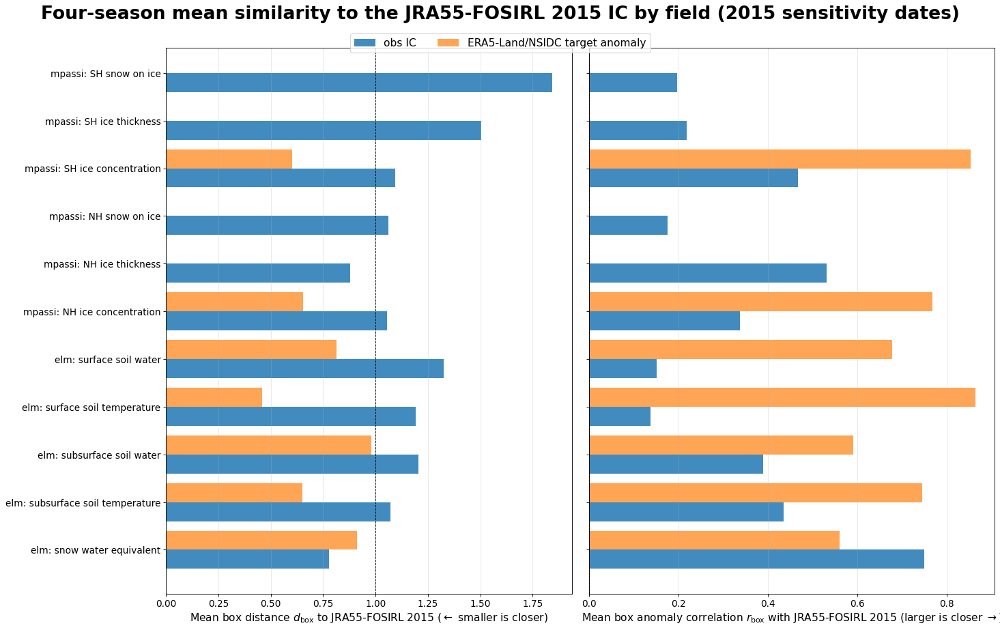

In [13]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14
PANEL_SIZE = None
# ---------------------------------------------------------------------------------------------
similarity = pd.concat([
    ice.field_similarity_table(plans[d], int(d[:4]), {METHOD: selections[d]["elm"]}, obs_plans={EVAL_OBS["label"]: plans[d]},
                               states={METHOD: states[d]}, box=BOX, cache_dir=CACHE_DIR)
    for d in EVAL_DATES if d in plans
], ignore_index=True)
ice.save_table(similarity, "field_similarity", DIAG, SAVE_DIAG)
mean_by_source = (similarity.groupby(["component", "field", "source"])
                  [["d_box", "r_box", "d_grid", "r_grid", "RMSE", "PCC", "bias"]].mean())
ipd.display(mean_by_source.round(3))

fig = ice.plot_field_similarity_bars(similarity, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
ice.save_fig(fig, "2015_field_similarity_bars", DIAG, SAVE_DIAG, dpi=FIG_DPI)
plt.show()

### 5.4 Global and hemispheric totals against JRA55-FOSIRL 2015

In [14]:
global_summary = ice.global_summary_table(EVAL_DATES, {(METHOD, d): selections[d] for d in EVAL_DATES if d in plans},
                                          SRC_ROOT, src_prefix=SRC_PREFIX, components=COMPONENTS)
global_summary = global_summary.rename(columns={f"{METHOD} year": "year", METHOD: "value",
                                                f"{METHOD} - actual": "value - actual"})
ice.save_table(global_summary, "global_summary", DIAG, SAVE_DIAG)
ipd.display(global_summary.round(3))

[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/global_summary.csv


,target_date,component,quantity,actual_2015,year,value,value - actual
0,2015-02-01,elm,mean H2OSNO (mm),348.912,2014,349.446,0.534
1,2015-02-01,elm,snow-covered column fraction,0.626,2014,0.630,0.004
2,2015-02-01,elm,top-3-layer soil liquid (kg m-2),10.719,2014,10.602,-0.117
3,2015-02-01,elm,top-3-layer soil ice (kg m-2),35.257,2014,35.681,0.424
4,2015-02-01,elm,top soil layer T (K),270.704,2014,270.963,0.259
...,...,...,...,...,...,...,...
63,2015-11-01,mpassi,NH snow volume (1e3 km3),0.591,2014,0.931,0.341
64,2015-11-01,mpassi,SH ice area (1e6 km2),15.250,2014,16.218,0.968
65,2015-11-01,mpassi,SH ice extent >15% (1e6 km2),18.094,2014,19.151,1.056
66,2015-11-01,mpassi,SH ice volume (1e3 km3),21.476,2014,23.439,1.963


### 5.5 `BOX`-scale standardized anomaly maps (`EXAMPLE_DATE`)

What the distance metric sees. Columns: the JRA55-FOSIRL 2015 IC (the reference), the observed anomaly (the
target), and the initial condition; box PCC and RMSE compare the reference and the initial condition with the
observed anomaly.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/box15x30_z_mpassi_nh_ice_concentration_20150201.png


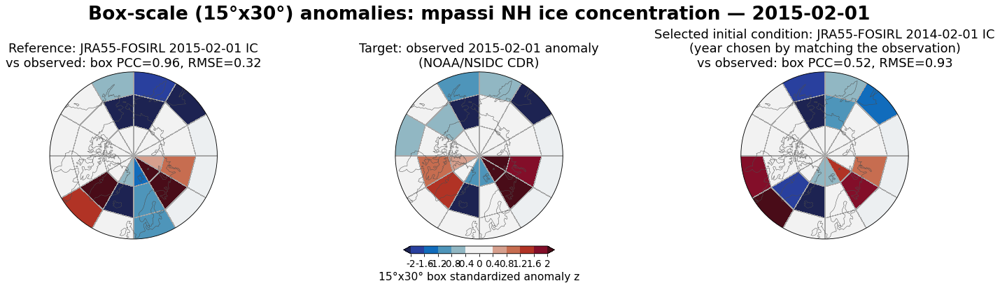

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/box15x30_z_mpassi_sh_ice_concentration_20150201.png


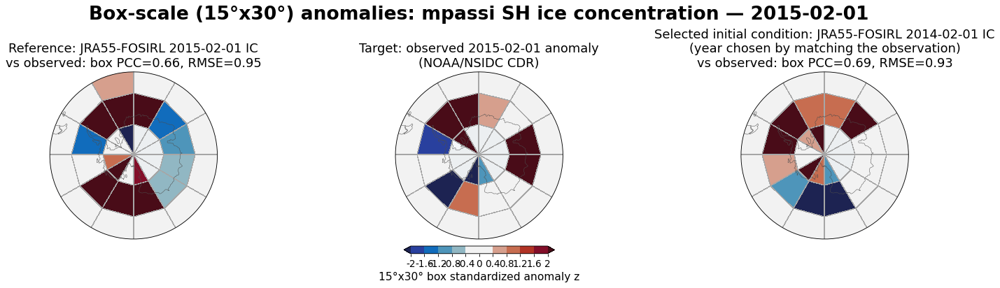

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/box15x30_z_elm_snow_water_equivalent_20150201.png


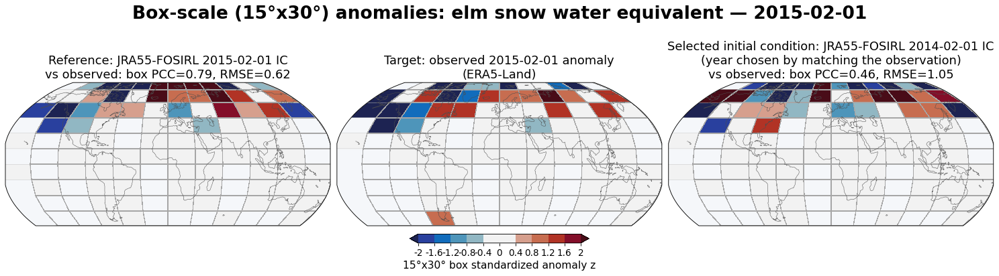

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/box15x30_z_elm_surface_soil_water_20150201.png


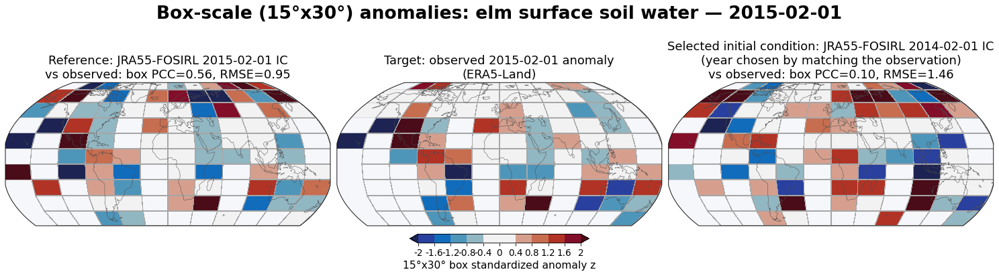

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/box15x30_z_elm_subsurface_soil_water_20150201.png


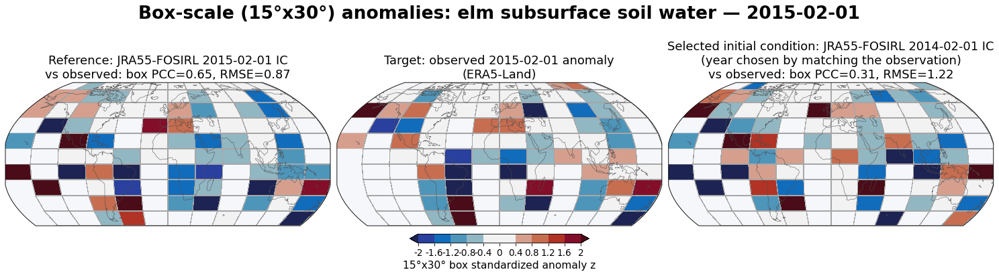

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/box15x30_z_elm_surface_soil_temperature_20150201.png


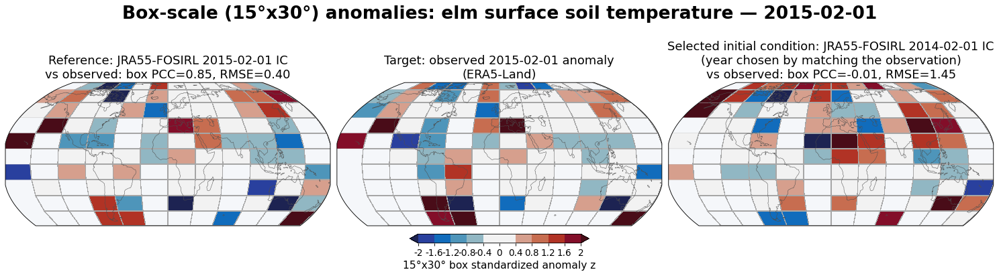

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/box15x30_z_elm_subsurface_soil_temperature_20150201.png


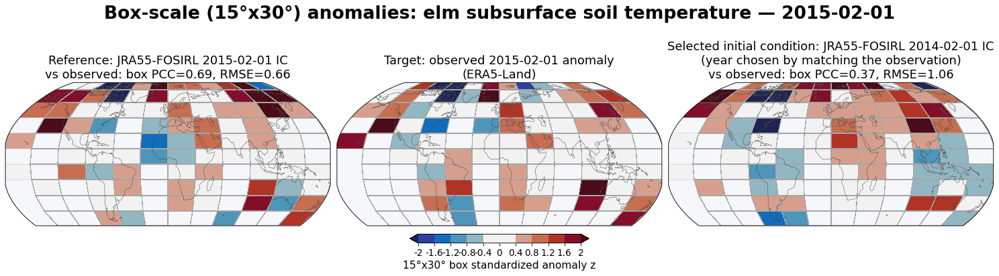

In [15]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14
PANEL_SIZE = None
Z_LIM = 2.0          # color range of the box anomaly maps
BOX_FIELDS = [("mpassi", "NH ice concentration"), ("mpassi", "SH ice concentration"),
              ("elm", "snow water equivalent"), ("elm", "surface soil water"), ("elm", "subsurface soil water"),
              ("elm", "surface soil temperature"), ("elm", "subsurface soil temperature")]
# ---------------------------------------------------------------------------------------------
for comp, name in BOX_FIELDS:
    sp = ice.prepare_spatial_field(plans[EXAMPLE_DATE], comp, name, int(EXAMPLE_DATE[:4]),
                                   {METHOD: selections[EXAMPLE_DATE]["elm"]}, obs_plans={EVAL_OBS["label"]: plans[EXAMPLE_DATE]},
                                   states={METHOD: states[EXAMPLE_DATE]}, box=BOX, cache_dir=CACHE_DIR)
    fig = ice.plot_box_spatial(sp, z_lim=Z_LIM, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"box{BOX[0]:g}x{BOX[1]:g}_z_{comp}_{ice.slugify(name)}_{EXAMPLE_DATE.replace('-', '')}",
                 DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

## 6. Native-mesh maps

Plotted directly on the model meshes with [`mosaic`](https://docs.e3sm.org/mosaic/): the unstructured
MPAS-Seaice mesh (`IcoswISC30E3r5`) in polar stereographic projections and the ELM `grid1d` land cells.

### 6.1 MPAS-Seaice: state and error (`EXAMPLE_DATE`)

NH (top) and SH (bottom): the JRA55-FOSIRL 2015 IC (reference), the initial condition (PCC and RMSE against
the reference), and the error (initial condition minus reference).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/mpassi_state_diff_ice_concentration_20150201.png


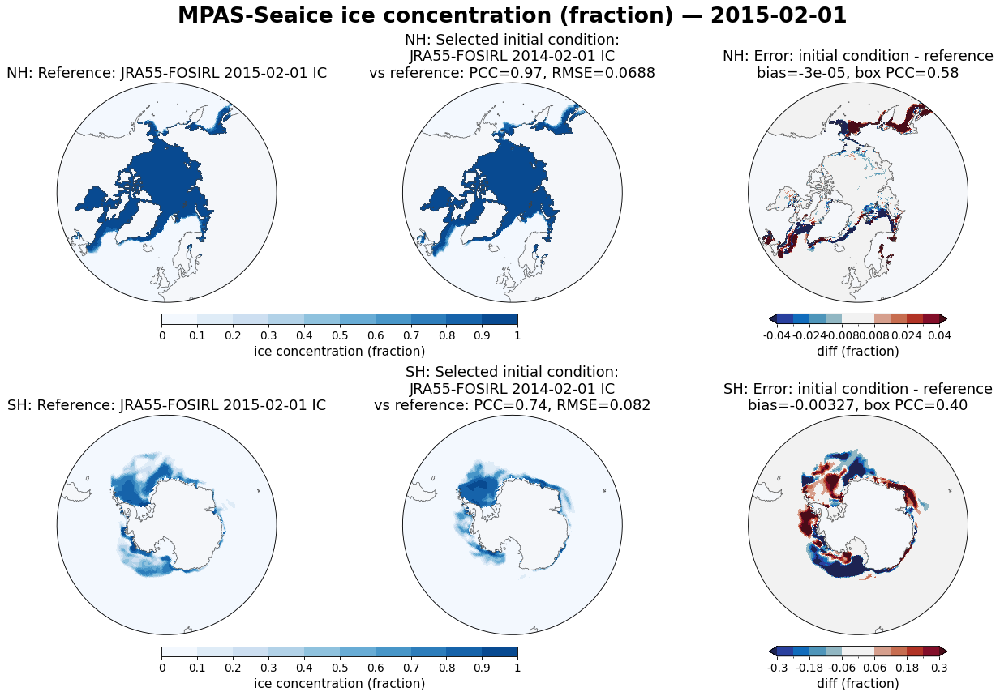

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/mpassi_state_diff_ice_thickness_20150201.png


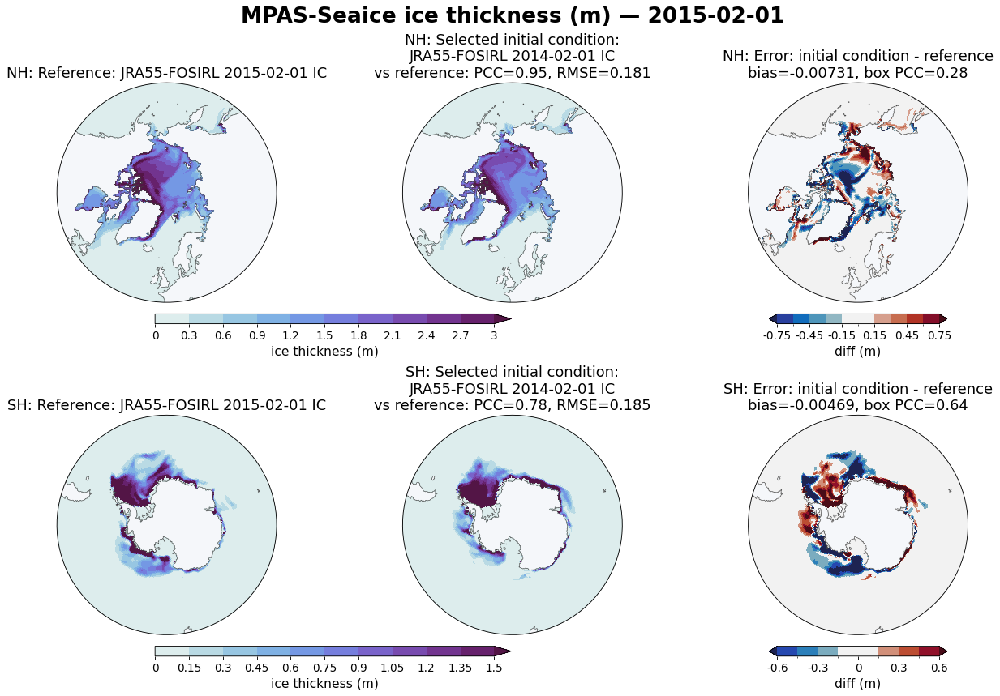

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/mpassi_state_diff_snow_on_ice_20150201.png


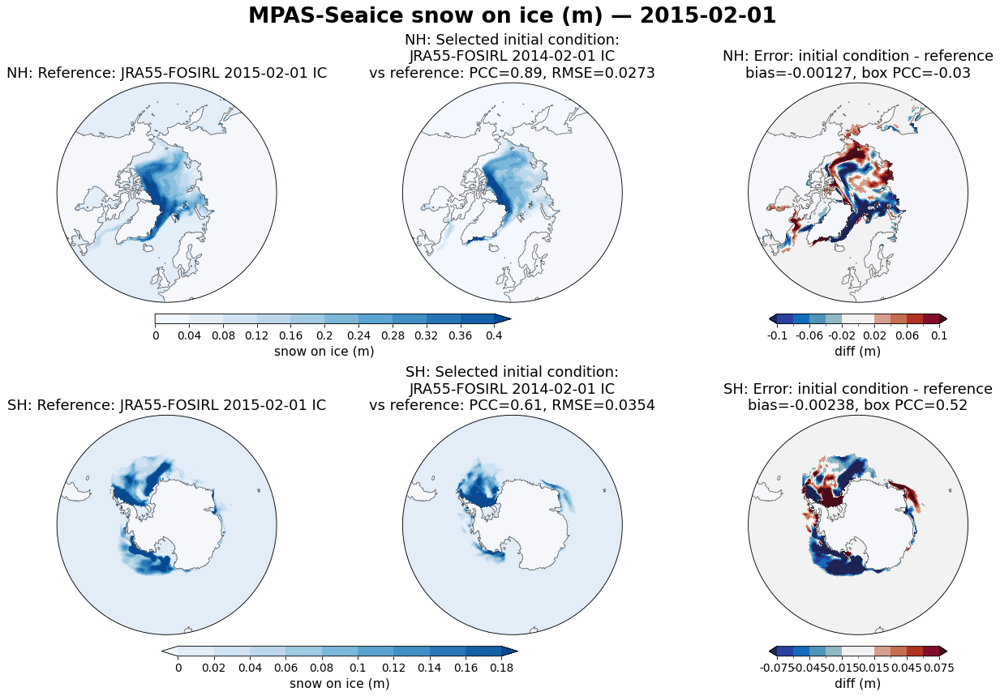

In [16]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14
PANEL_SIZE = None
QUANTITIES = ["ice concentration", "ice thickness", "snow on ice"]   # each plotted for NH and SH
# ---------------------------------------------------------------------------------------------
mesh_file = cr.source_file(SRC_ROOT, SRC_PREFIX, "mpassi", int(EXAMPLE_DATE[:4]), EXAMPLE_DATE[5:])
mpassi_desc = ice.build_mpassi_descriptors(mesh_file)
spatial_mpassi = {}
for quantity in QUANTITIES:
    for hemi in ("NH", "SH"):
        name = f"{hemi} {quantity}"
        spatial_mpassi[name] = ice.prepare_spatial_field(
            plans[EXAMPLE_DATE], "mpassi", name, int(EXAMPLE_DATE[:4]), {METHOD: selections[EXAMPLE_DATE]["mpassi"]},
            obs_plans={EVAL_OBS["label"]: plans[EXAMPLE_DATE]}, states={METHOD: states[EXAMPLE_DATE]},
            box=BOX, cache_dir=CACHE_DIR)
    fig = ice.plot_mpassi_spatial([spatial_mpassi[f"NH {quantity}"], spatial_mpassi[f"SH {quantity}"]], mpassi_desc,
                                  kind="state_and_diff", fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"mpassi_state_diff_{ice.slugify(quantity)}_{EXAMPLE_DATE.replace('-', '')}",
                 DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 6.2 MPAS-Seaice: standardized anomalies (`EXAMPLE_DATE`)

The JRA55-FOSIRL 2015 IC (the reference), the observed anomaly (the target), and the initial condition, as
standardized anomalies z; PCC, RMSE, and box PCC compare the reference and the initial condition with the
observed anomaly. Fields without an observation (ice thickness) compare the initial condition with the
JRA55-FOSIRL 2015 IC.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/mpassi_z_ice_concentration_20150201.png


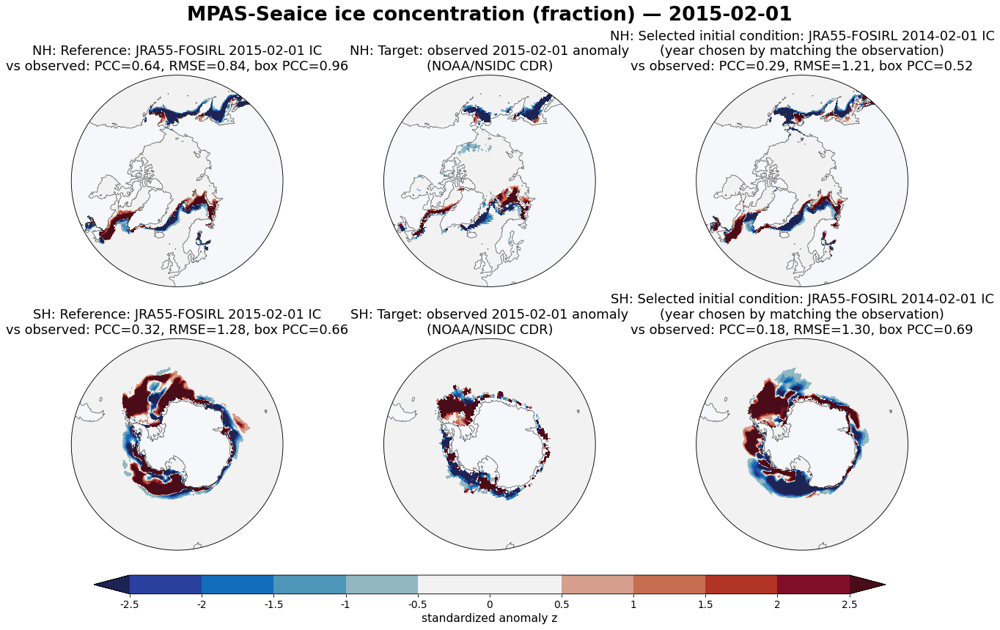

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/mpassi_z_ice_thickness_20150201.png


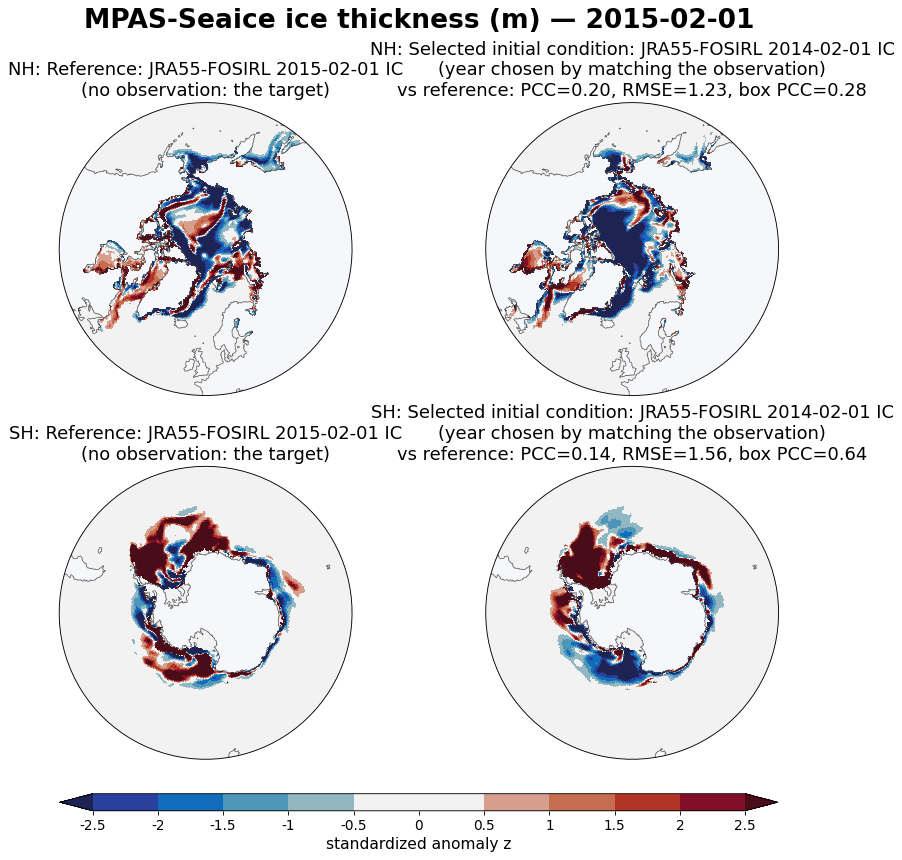

In [17]:
Z_LIM = 2.5          # color range of the standardized anomaly maps
for quantity in ["ice concentration", "ice thickness"]:
    fig = ice.plot_mpassi_spatial([spatial_mpassi[f"NH {quantity}"], spatial_mpassi[f"SH {quantity}"]], mpassi_desc,
                                  kind="z", z_lim=Z_LIM, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"mpassi_z_{ice.slugify(quantity)}_{EXAMPLE_DATE.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 6.3 MPAS-Seaice: four 2015 dates

JRA55-FOSIRL 2015 sea-ice concentration and the error of the initial condition on each 2015 date.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/mpassi_4seasons_nh_ice_concentration_2015.png


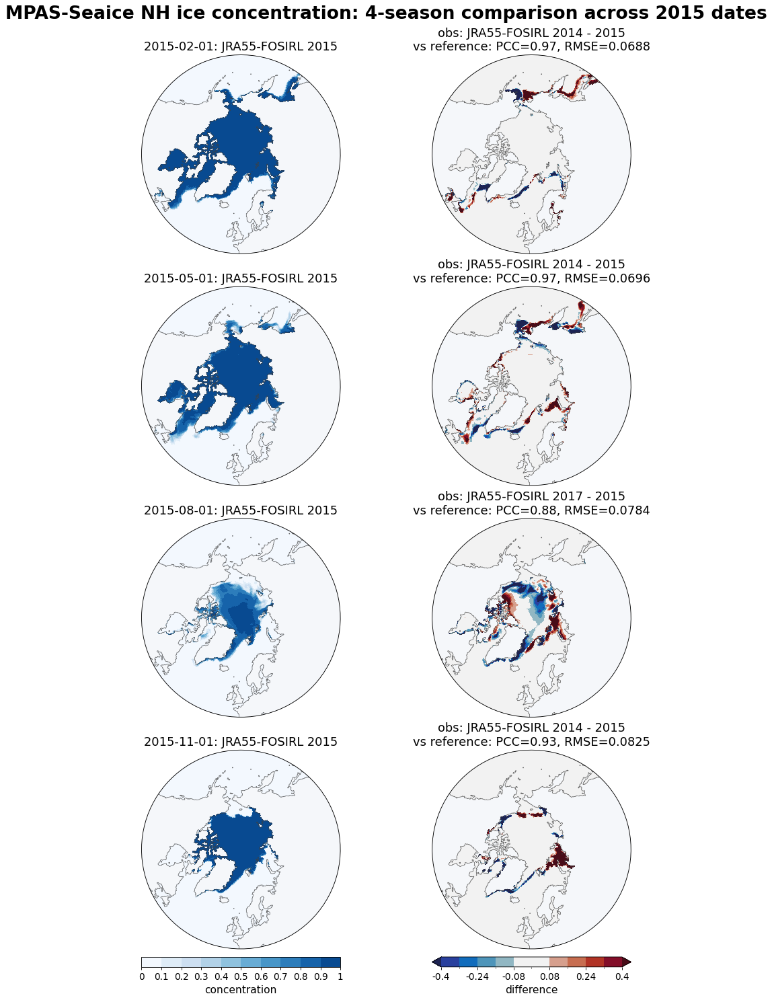

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/mpassi_4seasons_sh_ice_concentration_2015.png


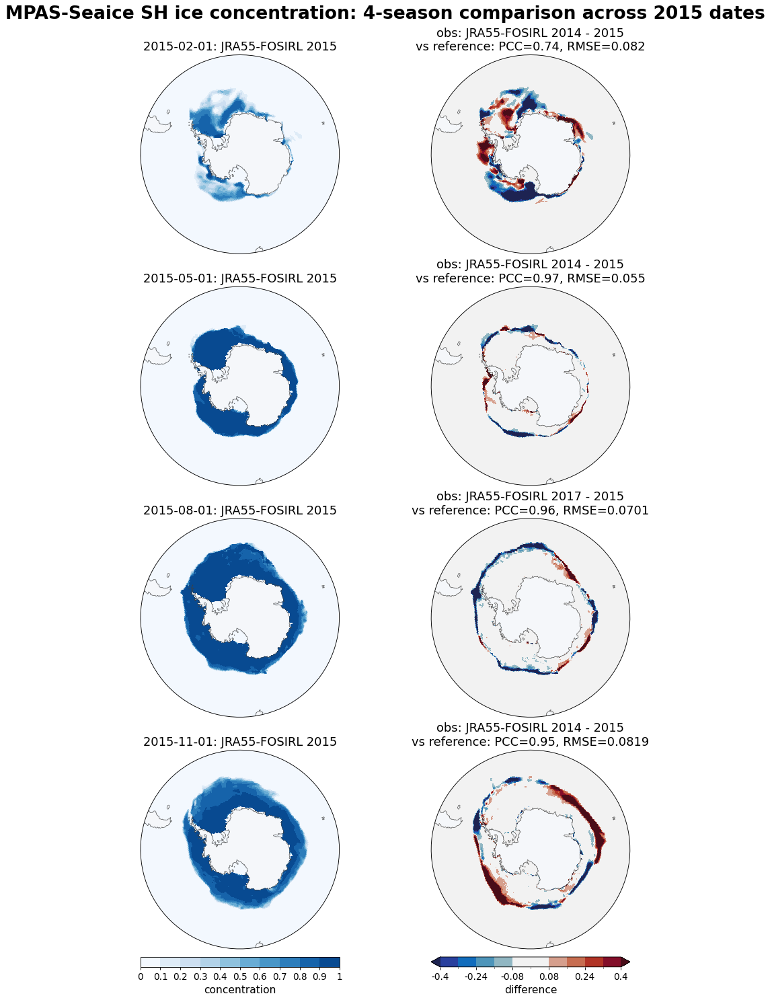

In [18]:
DIFF_LIM = 0.4       # color range of the concentration differences
for name in ["NH ice concentration", "SH ice concentration"]:
    fig = ice.plot_mpassi_four_seasons(name, EVAL_DATES, eval_plans, {(METHOD, d): selections[d] for d in EVAL_DATES},
                                       mpassi_desc, states={d: {METHOD: states[d]} for d in EVAL_DATES},
                                       box=BOX, cache_dir=CACHE_DIR, diff_lim=DIFF_LIM, fontsize=FONTSIZE,
                                       panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"mpassi_4seasons_{ice.slugify(name)}_2015", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 6.4 ELM: state and error (`MAP_DATES`)

Rows: snow water equivalent, surface and subsurface soil water, surface and subsurface soil temperature.
Columns: the JRA55-FOSIRL 2015 IC (reference), the candidate-year climatology (baseline, no selection), the
initial condition (PCC and RMSE against the reference), and the error in percent of the reference (bias and
box PCC in the title).

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_state_diff_20150201.png


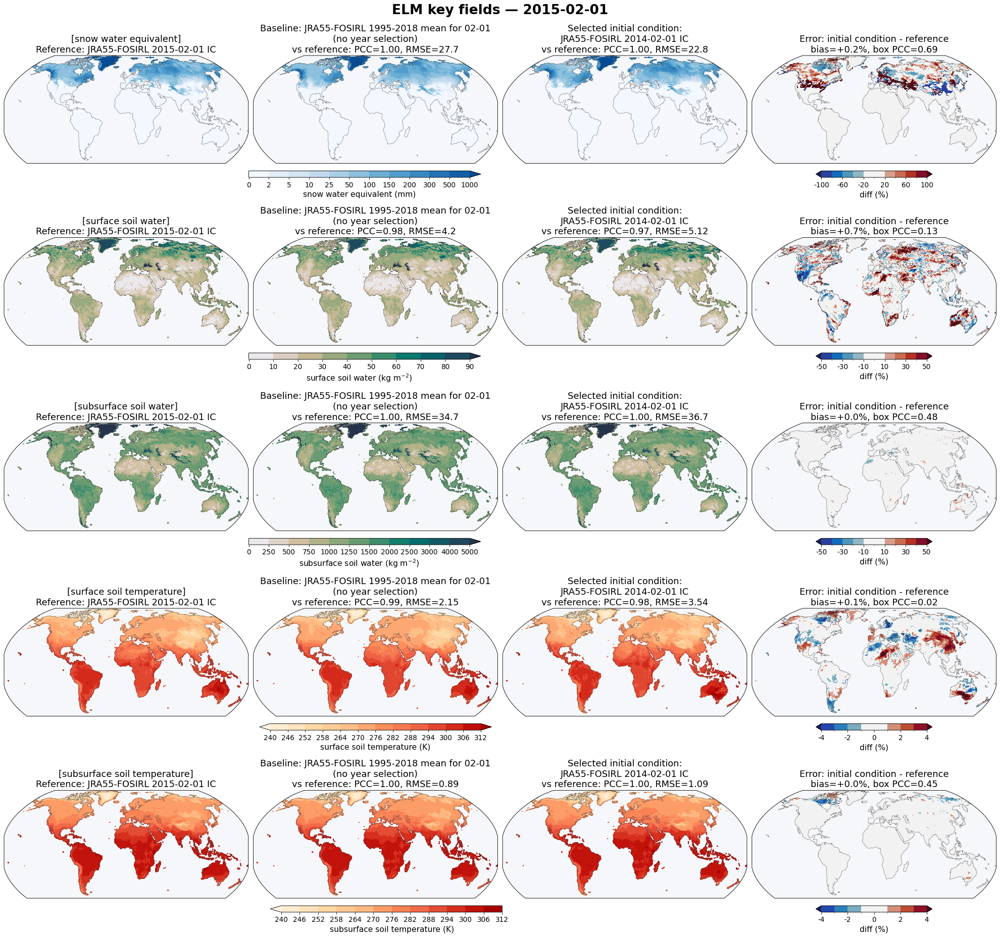

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_state_diff_20150501.png


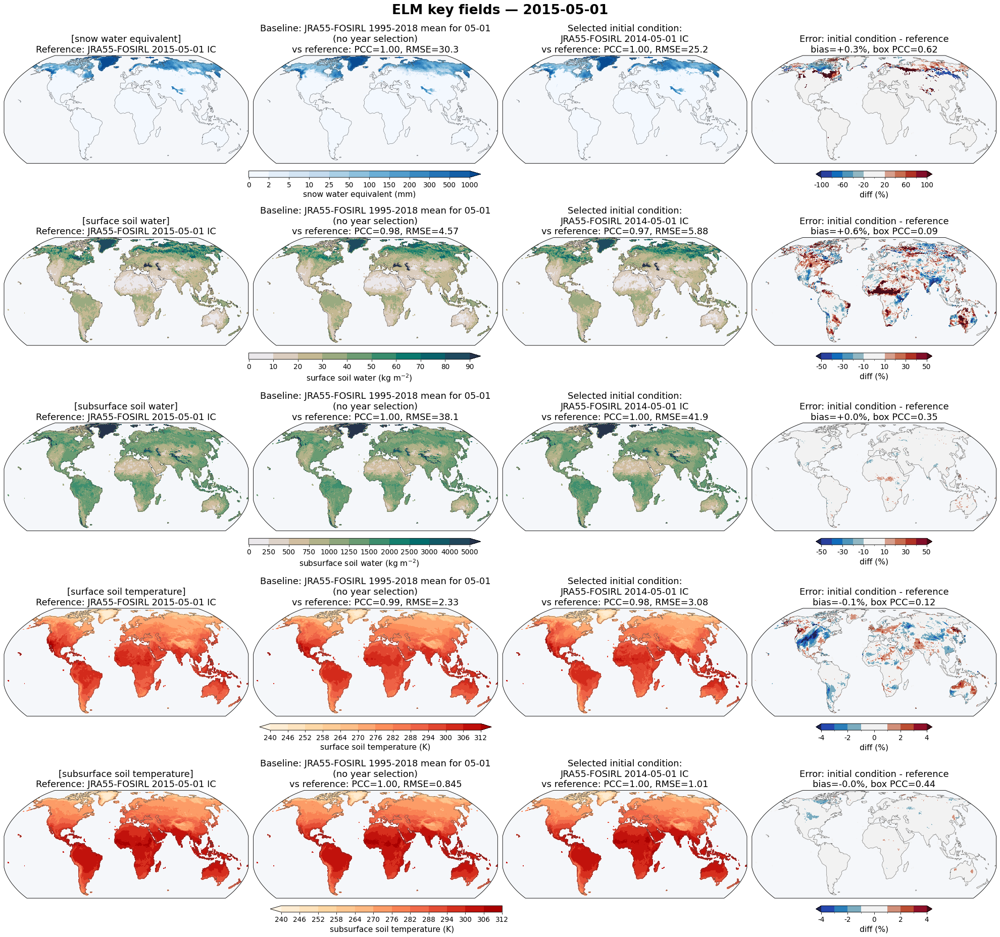

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_state_diff_20150801.png


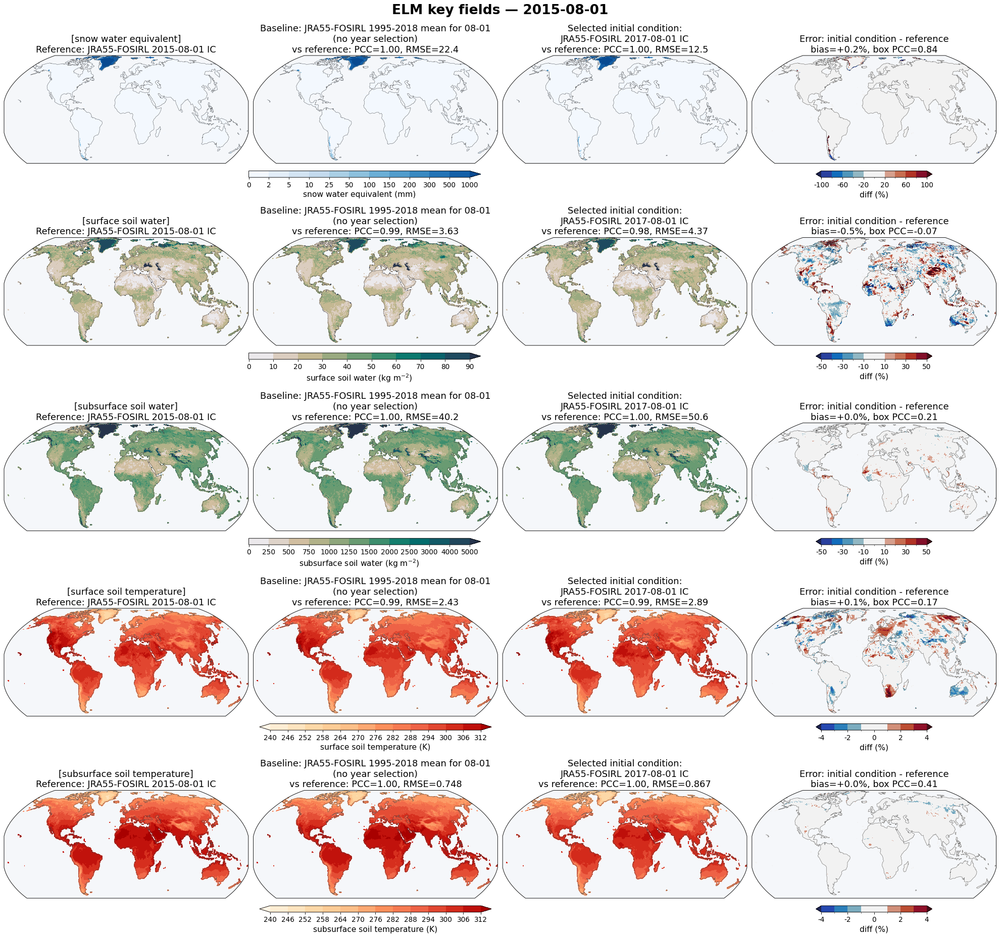

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_state_diff_20151101.png


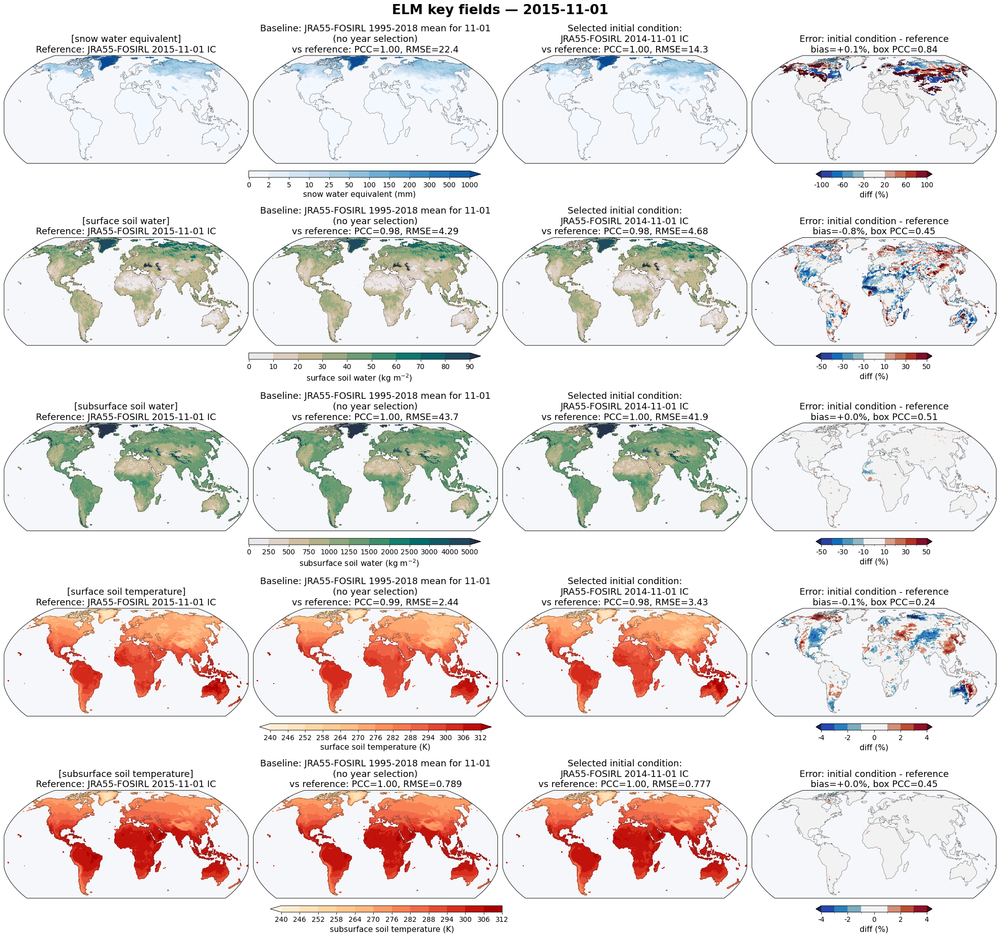

In [19]:
# ---- Figure setup ---------------------------------------------------------------------------
FONTSIZE = 14
PANEL_SIZE = None
ELM_FIELDS = ["snow water equivalent", "surface soil water", "subsurface soil water",
              "surface soil temperature", "subsurface soil temperature"]
# ---------------------------------------------------------------------------------------------
points = cr.comparison_points(plans[EXAMPLE_DATE], "elm", CACHE_DIR)
elm_desc = ice.build_elm_descriptor(points["lat"], points["lon"])
spatial_elm = {}
for date in MAP_DATES:
    spatial_elm[date] = {
        name: ice.prepare_spatial_field(plans[date], "elm", name, int(date[:4]), {METHOD: selections[date]["elm"]},
                                        obs_plans={EVAL_OBS["label"]: plans[date]}, states={METHOD: states[date]},
                                        box=BOX, cache_dir=CACHE_DIR)
        for name in ELM_FIELDS
    }
    fig = ice.plot_elm_spatial([spatial_elm[date][f] for f in ELM_FIELDS], elm_descriptor=elm_desc,
                               kind="state_and_diff", fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"elm_state_diff_{date.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 6.5 ELM: state and error against the observation (`MAP_DATES`)

The target of this method in model units: the observed anomaly $t$ placed on the model climatology,
$\bar x_i + t_i S$ (the JRA55-FOSIRL 1995-2018 mean plus the observed standardized anomaly times the model
spread), so it can be mapped and differenced with the model states despite the unit, layer-depth, and
climatology differences between the model and the observations. Columns: the JRA55-FOSIRL 2015 IC (reference),
the observed target (PCC and RMSE of the reference against it), the initial condition (PCC and RMSE against the
target), and the error of the initial condition from the target in percent (bias, and the RMS difference of
the standardized anomalies at grid points and on `BOX` boxes, which the selection minimizes). Section 6.4
scores the same initial condition against the JRA55-FOSIRL 2015 IC instead.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_state_obs_diff_20150201.png


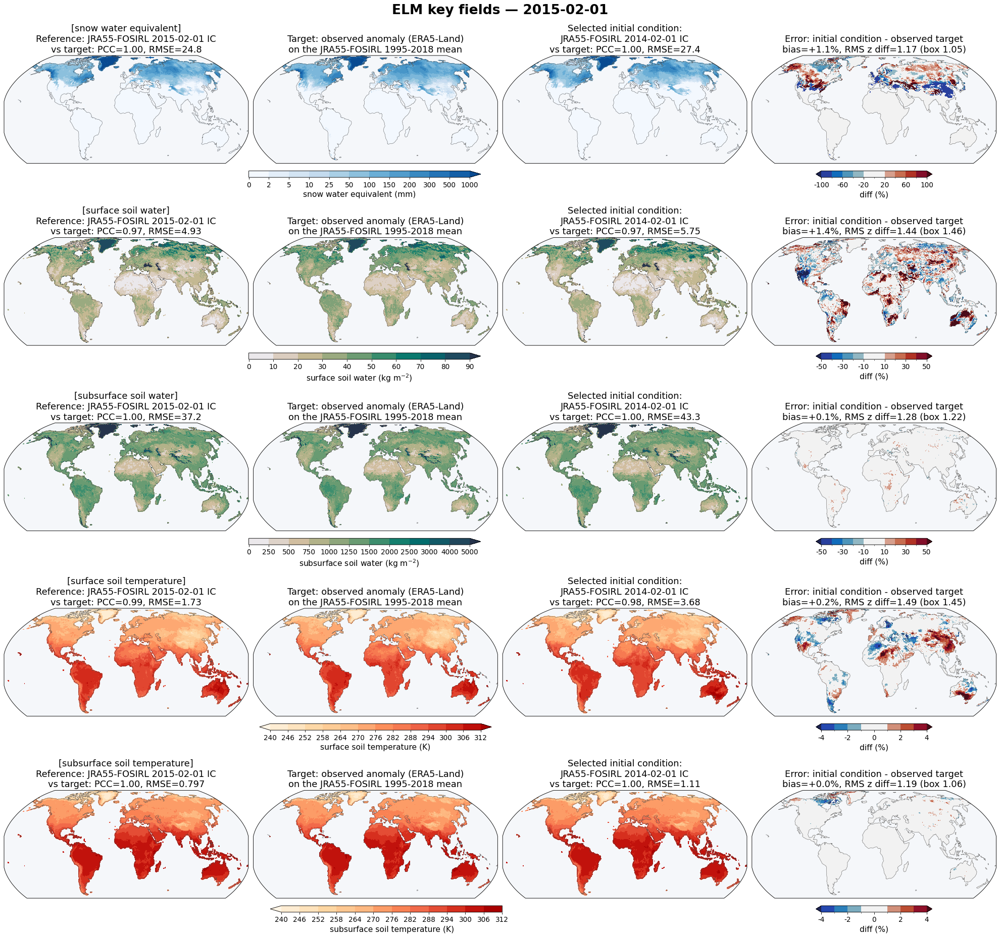

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_state_obs_diff_20150501.png


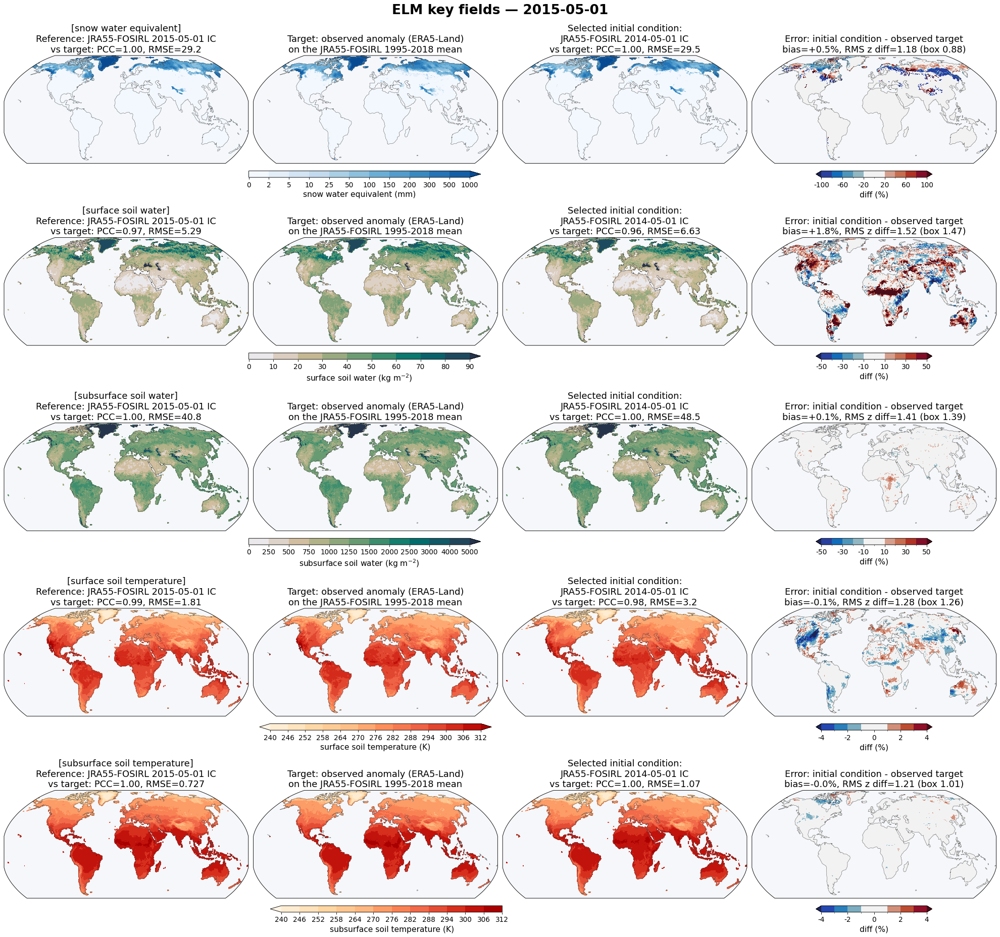

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_state_obs_diff_20150801.png


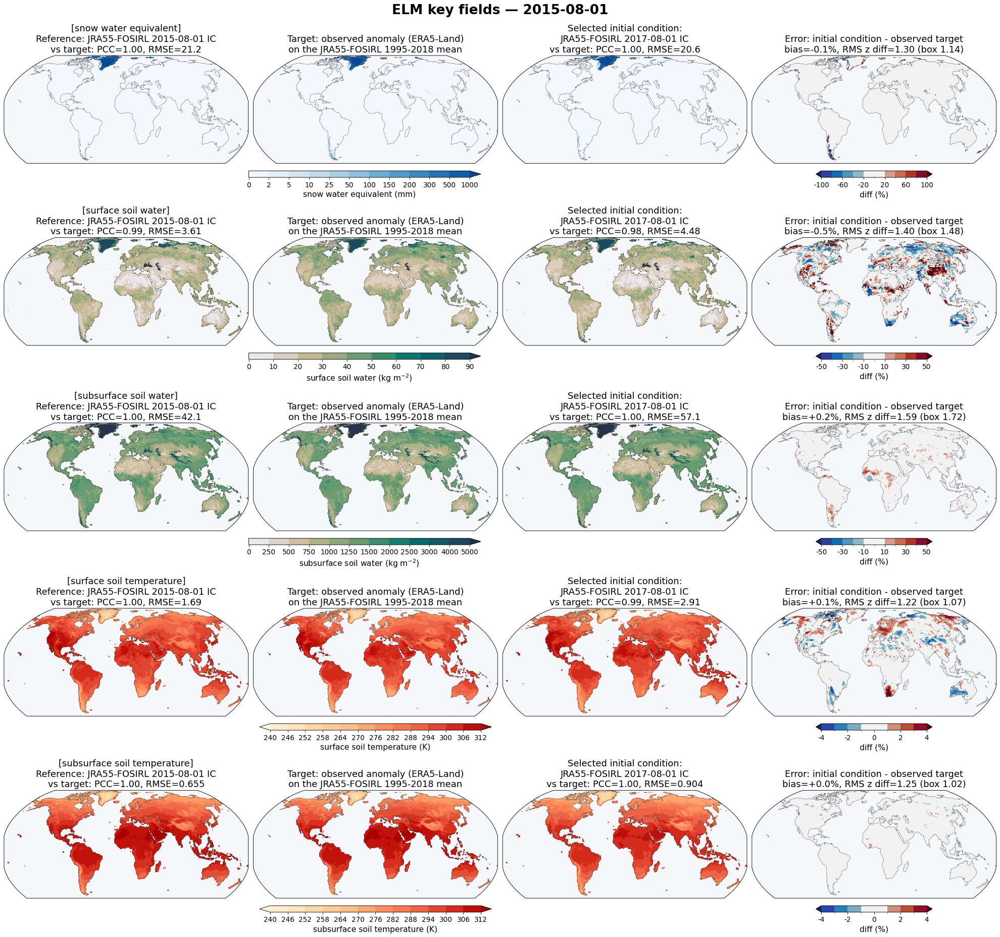

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_state_obs_diff_20151101.png


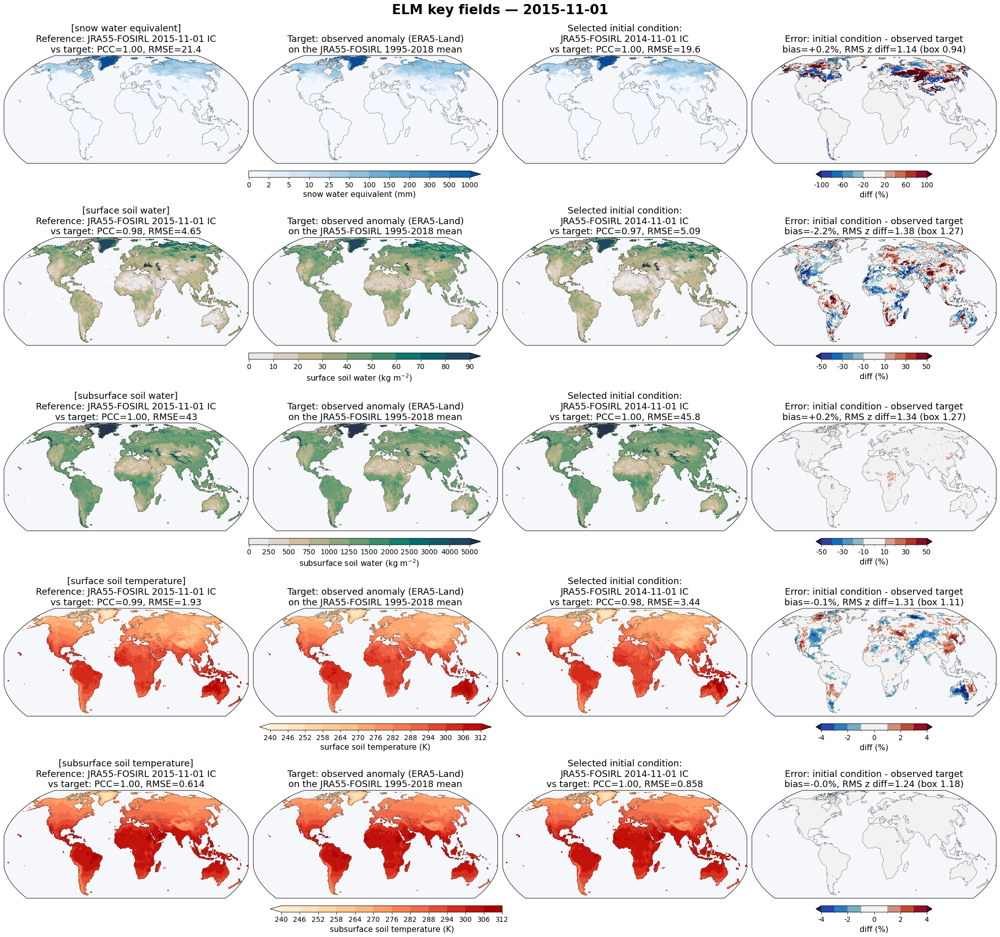

In [20]:
for date in MAP_DATES:
    fig = ice.plot_elm_spatial([spatial_elm[date][f] for f in ELM_FIELDS], elm_descriptor=elm_desc,
                               kind="state_and_diff", reference="observation",
                               fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"elm_state_obs_diff_{date.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 6.6 ELM: standardized anomalies (`MAP_DATES`)

The JRA55-FOSIRL 2015 IC (the reference), the observed anomaly (the target), and the initial condition; PCC,
RMSE (in standard deviations), and box PCC compare the reference and the initial condition with the observed
anomaly.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_z_20150201.png


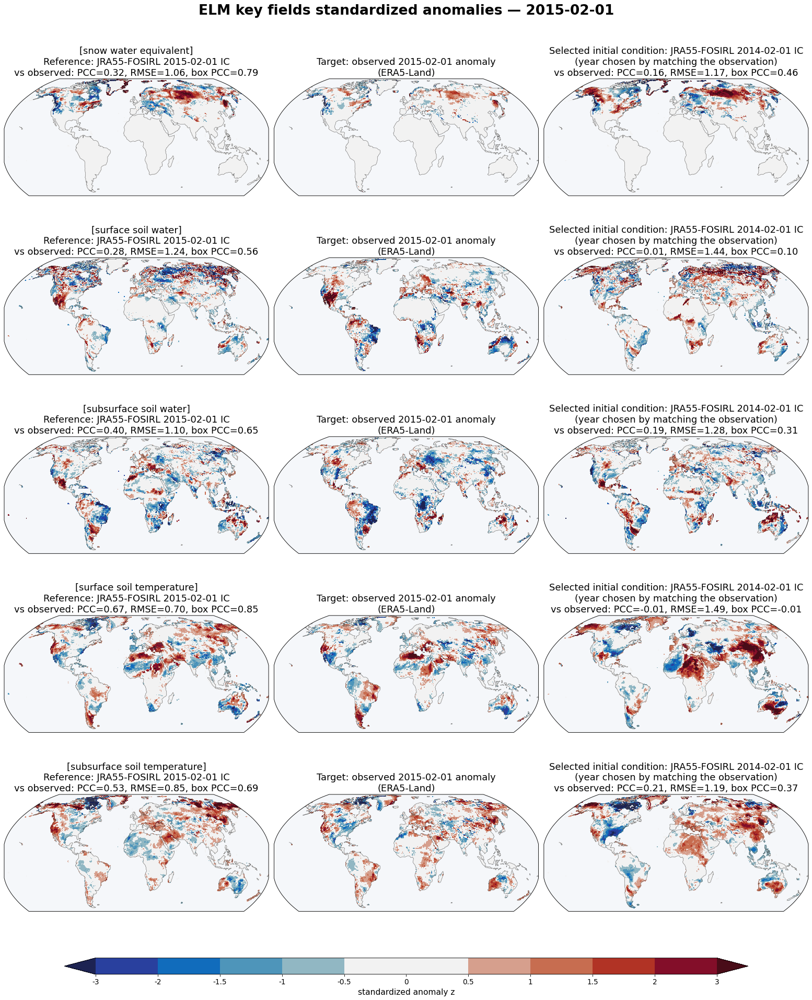

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_z_20150501.png


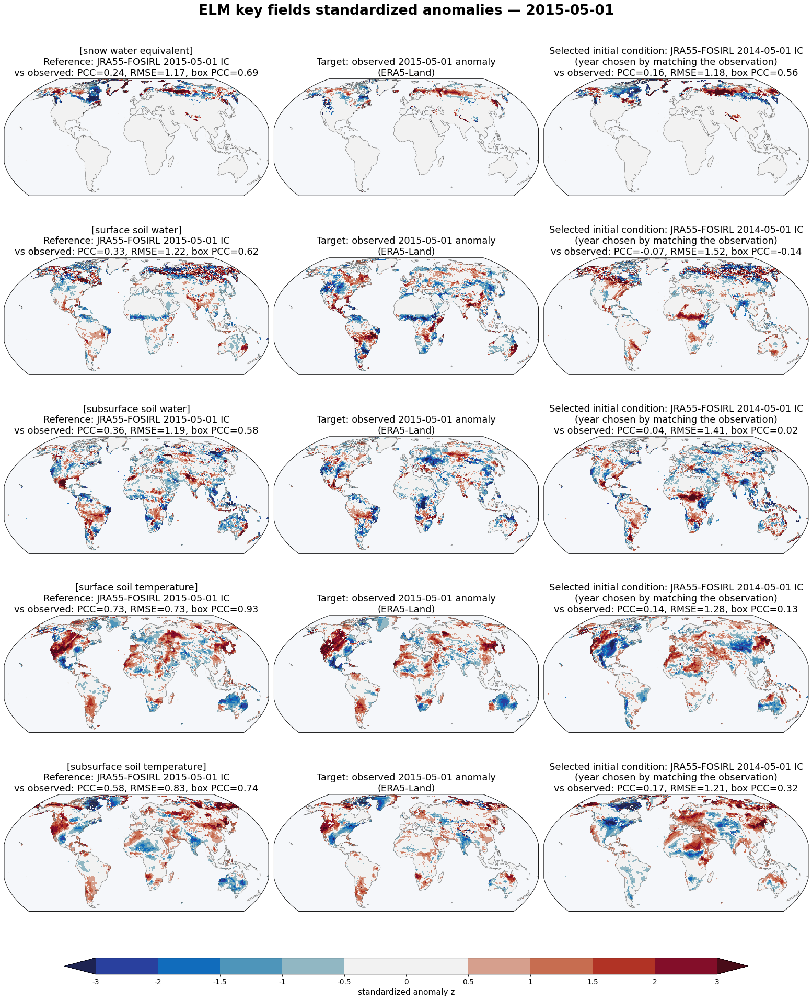

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_z_20150801.png


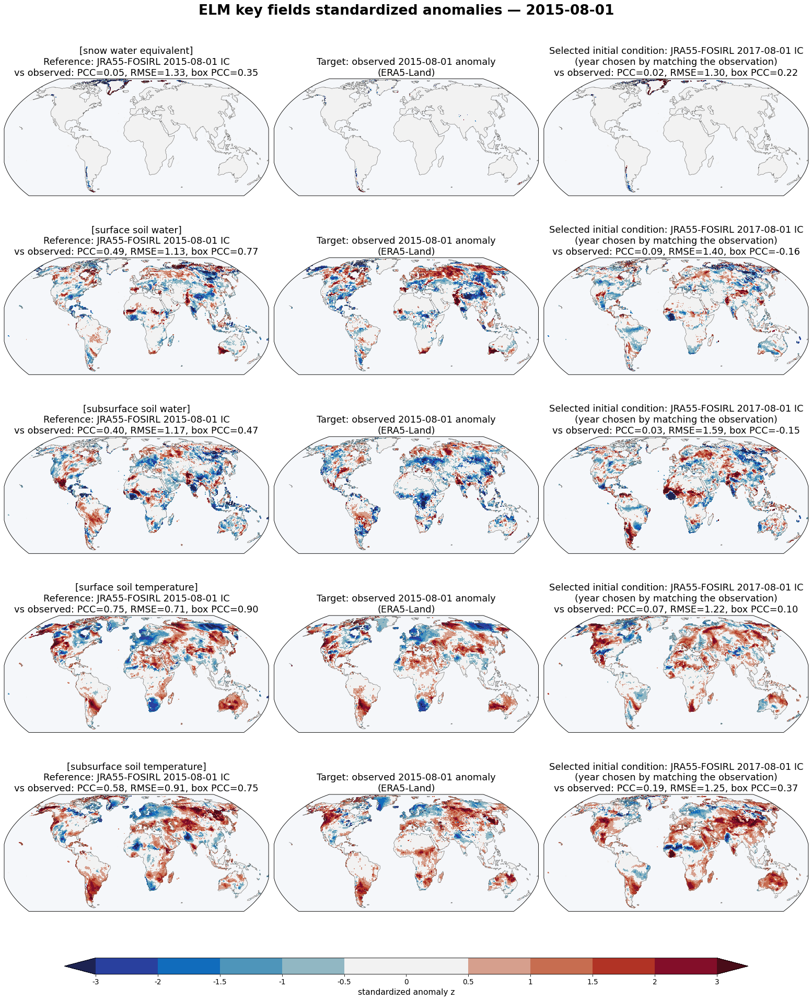

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_z_20151101.png


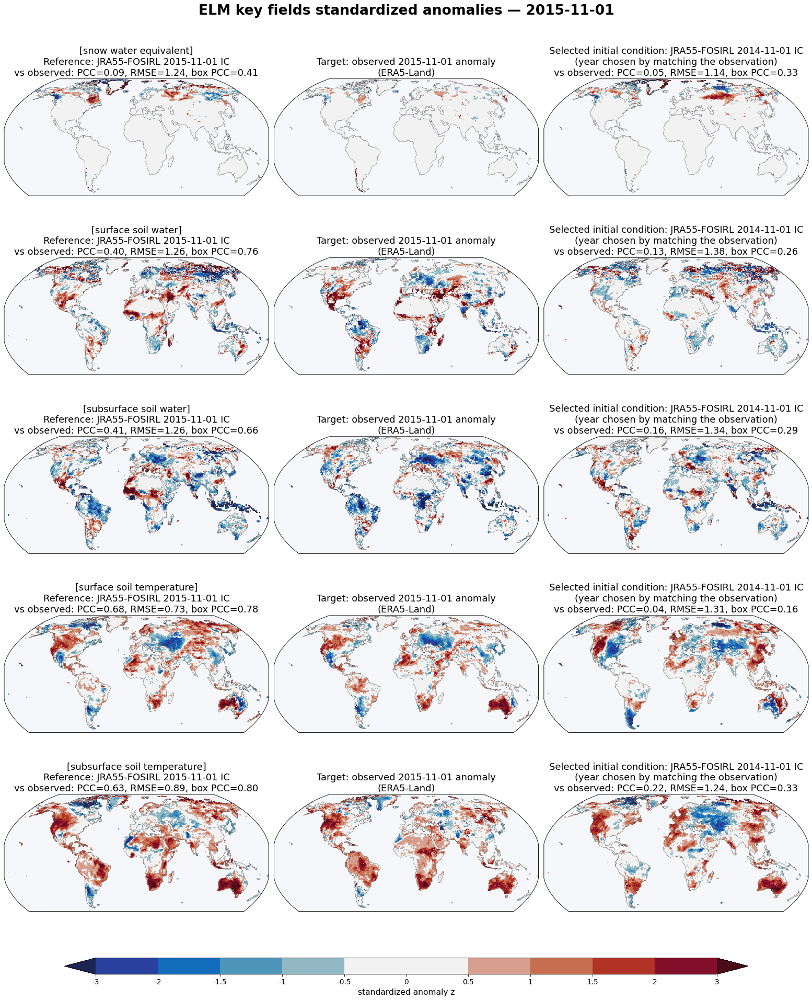

In [21]:
Z_LEVELS = [-3, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 3]
for date in MAP_DATES:
    fig = ice.plot_elm_spatial([spatial_elm[date][f] for f in ELM_FIELDS], elm_descriptor=elm_desc, kind="z",
                               z_lim=Z_LEVELS[-1], z_levels=Z_LEVELS, fontsize=FONTSIZE, panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"elm_z_{date.replace('-', '')}", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

### 6.7 ELM: four 2015 dates

Standardized anomalies of each land field on the four 2015 dates: the JRA55-FOSIRL 2015 IC (the reference),
the observed anomaly (the target), and the initial condition.

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_4seasons_z_snow_water_equivalent_2015.png


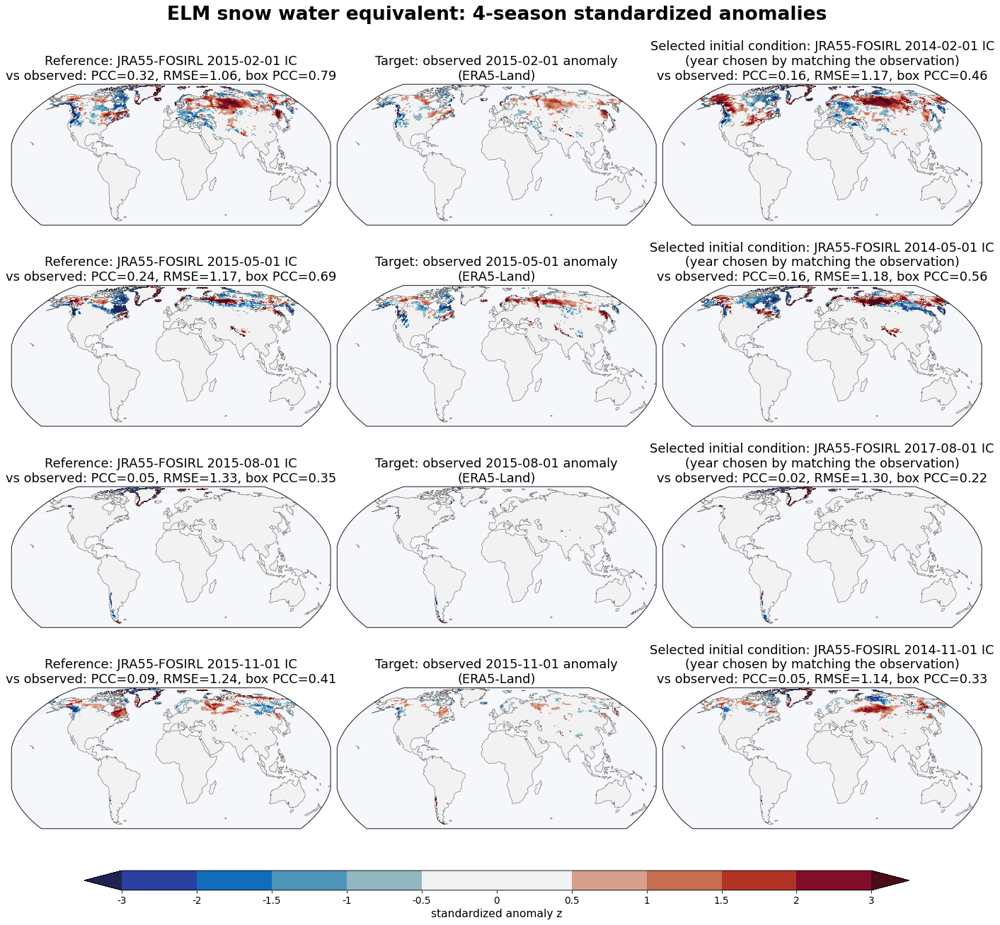

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_4seasons_z_surface_soil_water_2015.png


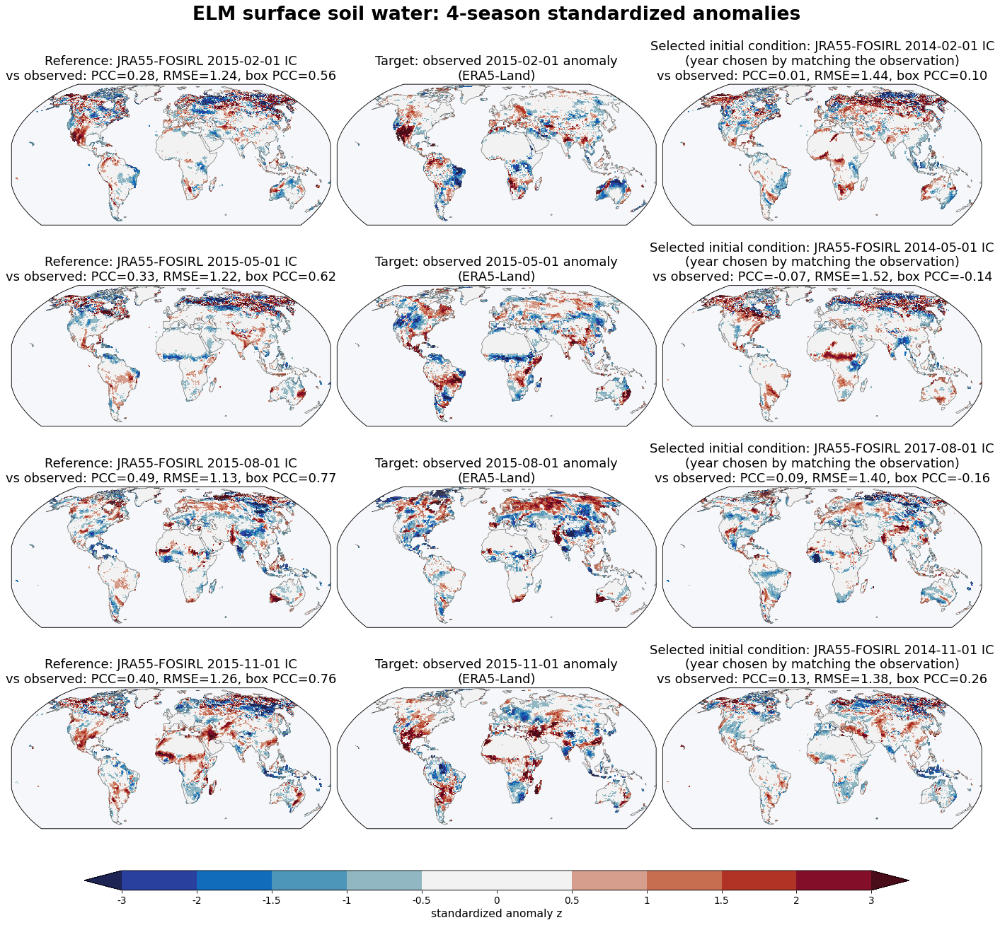

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_4seasons_z_subsurface_soil_water_2015.png


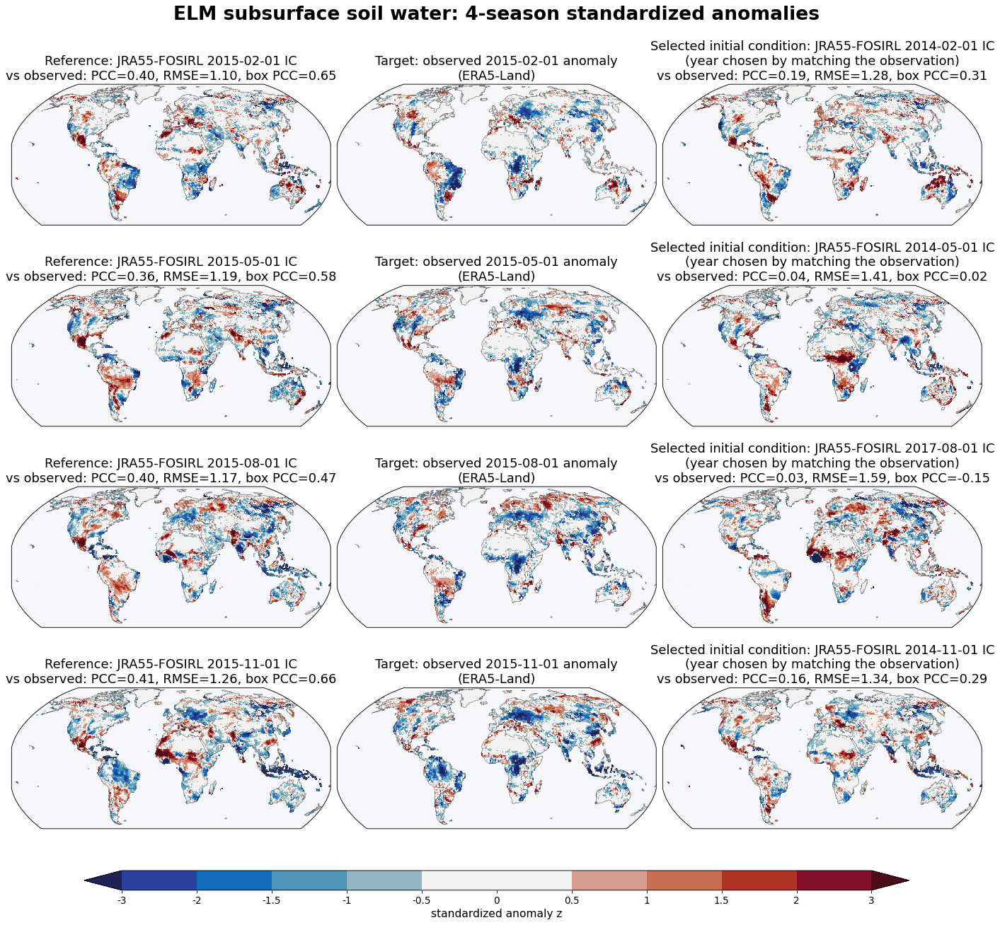

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_4seasons_z_surface_soil_temperature_2015.png


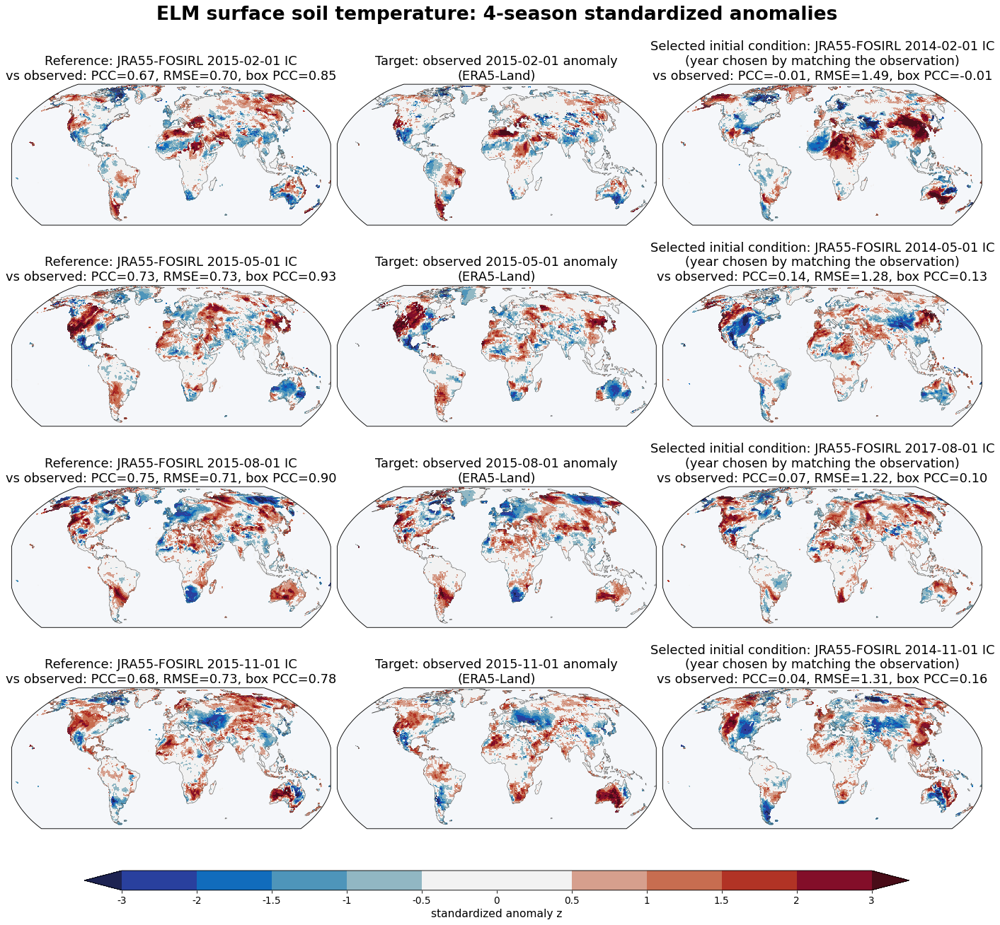

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/figure/elm_4seasons_z_subsurface_soil_temperature_2015.png


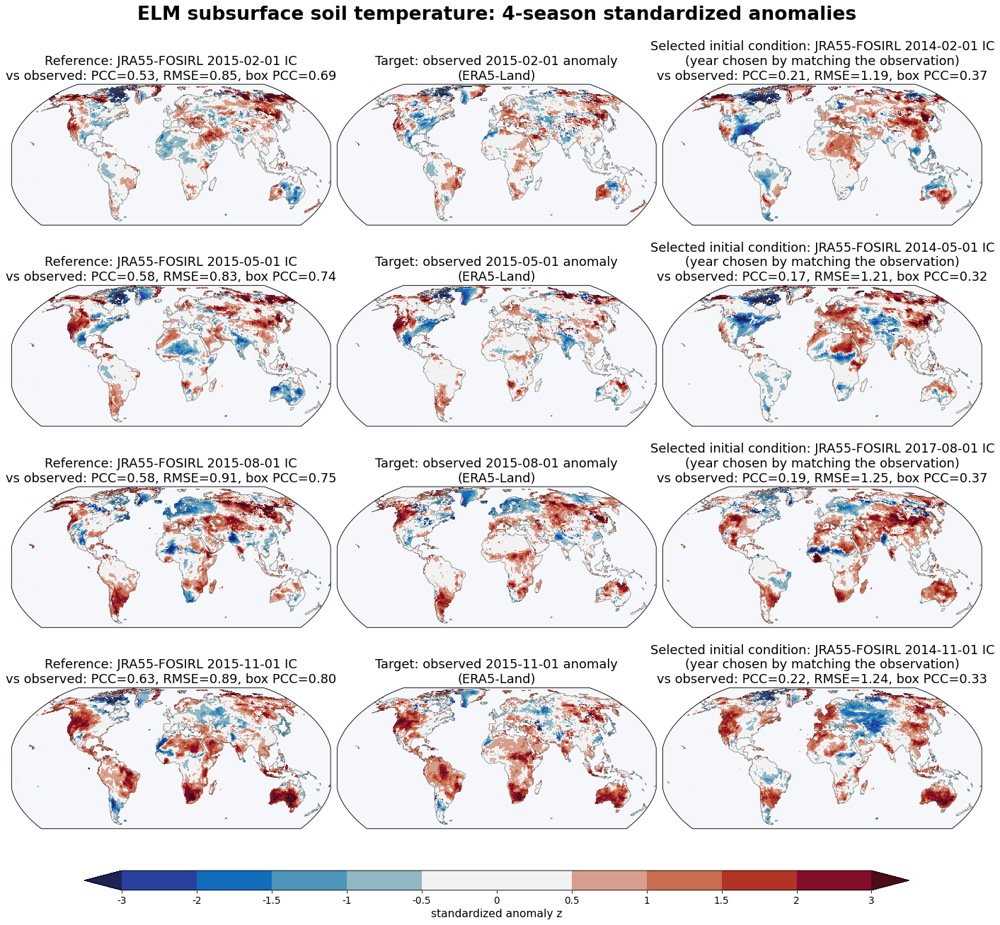

In [22]:
Z_LIM = 2.5
for name in ELM_FIELDS:
    fig = ice.plot_elm_four_seasons(name, EVAL_DATES, eval_plans, {(METHOD, d): selections[d] for d in EVAL_DATES},
                                    elm_desc, obs_refs={METHOD: EVAL_OBS["label"]},
                                    states={d: {METHOD: states[d]} for d in EVAL_DATES},
                                    box=BOX, cache_dir=CACHE_DIR, z_lim=Z_LIM, fontsize=FONTSIZE,
                                    panel_size=PANEL_SIZE)
    ice.save_fig(fig, f"elm_4seasons_z_{ice.slugify(name)}_2015", DIAG, SAVE_DIAG, dpi=FIG_DPI)
    plt.show()

## 7. Save the outputs for comparing the methods

Written to `DIAG_ROOT/<METHOD>/data/` in the same layout by 01, 02, and 03 (`util/ic_store.py`), and read by
`04_compare_ic_methods.ipynb`:

- `config.json`: the settings of this run;
- `selection.csv`: the year used for each date and component;
- `states_YYYYMMDD.npz`: the initial-condition key fields at model points, for every target date;
- `input_summary.csv`, `distances.csv`, `state_distance.csv`, `field_similarity.csv`, `global_summary.csv`
  (and `rank_summary.csv` for 01 and 02).

In [23]:
if SAVE_DIAG:
    config = {name: value for name, value in globals().items()
              if name.isupper() and isinstance(value, (str, int, float, bool, list, tuple, dict, Path, type(None)))}
    print(ic_store.save_config(DIAG_ROOT, METHOD, config))
    rows = [{"target_date": d, "component": c, "year": y, "role": "selected",
             "candidate years": f"{plans[d].candidate_years[0]}-{plans[d].candidate_years[-1]}",
             "climatology years": f"{plans[d].clim_years[0]}-{plans[d].clim_years[-1]}"}
            for d in plans for c, y in selections[d].items()]
    ice.save_table(pd.DataFrame(rows), "selection", DIAG, SAVE_DIAG)
    ice.save_table(inputs, "input_summary", DIAG, SAVE_DIAG)
    ice.save_table(pd.concat([t.reset_index().assign(target_date=d) for d, t in distances.items()]),
                   "distances", DIAG, SAVE_DIAG)
    ice.save_table(state_eval, "state_distance", DIAG, SAVE_DIAG)
    for date in states:
        print(ic_store.save_states(DIAG_ROOT, METHOD, date, states[date], selections[date]))

/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/config.json
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/selection.csv
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/input_summary.csv
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/distances.csv
[TABLE] /global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/state_distance.csv
/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/states_20150201.npz
/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/states_20150501.npz
/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/states_20150801.npz
/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/states_20151101.npz
/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/states_20260201.npz
/global/cfs/cdirs/e3sm/www/zhan391/E3SMv3_S2D/rtenso2026_ic/obs/data/states_20260501.npz
/global/cfs/

## 8. Key findings

Default settings: `OBS_SET = "era5land_nsidc"` (ERA5-Land for land, NOAA/NSIDC CDR for sea-ice
concentration), candidate and climatology years 1995-2018 (target year excluded), `BOX = (15, 30)`,
`BOX_SHIFTS = 4`, `MODE = "joint"`. All model states are JRA55-FOSIRL restarts.

**Table. Observation-matched years.** The selected and second-closest year, with the joint distance D from
the observed anomaly on 15°x30° boxes, and the median D over the candidates (a typical year).

| Date | Selected (D) | 2nd-closest (D) | Median D |
|---|---|---|---|
| 2015-02-01 | **2014** (1.14) | 2013 (1.21) | 1.40 |
| 2015-05-01 | **2014** (1.09) | 2008 (1.13) | 1.39 |
| 2015-08-01 | **2017** (1.15) | 2009 (1.20) | 1.37 |
| 2015-11-01 | **2014** (1.16) | 2004 (1.27) | 1.40 |
| 2026-02-01 | **2010** (1.29) | 2013 (1.32) | 1.56 |
| 2026-05-01 | **2011** (1.27) | 2007 (1.30) | 1.50 |
| 2026-08-01 | **2016** (1.34) | 2005 (1.38) | 1.55 |
| 2026-11-01 | observations not yet available | | |

1. **The observation-based selection finds the candidate closest to the JRA55-FOSIRL 2015 IC.** On all four
   2015 dates the selected year ranks 1 of 23 on the observed fields, and the observation-based distance ranks
   the candidates consistently with the true distance (rank correlation 0.71-0.94). With all key fields it
   ranks 1 except in Aug (7), where the unobserved sea-ice thickness and snow on ice favour 2009.
2. **The closest year matches the observed anomaly only partly.** Its D (1.09-1.34) is clearly below the
   median (1.37-1.56) but far from 0: no archive year reproduces the observed state.
3. **Field by field** (box pattern correlation with the JRA55-FOSIRL 2015 anomaly, mean over the 2015 dates):
   good for snow water equivalent (0.75), moderate for NH ice thickness (0.53), SH ice concentration (0.47),
   and subsurface soil temperature (0.44), weak for surface soil temperature (0.14), surface soil water (0.15),
   NH ice concentration (0.34), and subsurface soil water (0.39). The observed anomaly itself matches the
   JRA55-FOSIRL 2015 anomaly much better (0.56-0.86), which motivates `03_hybrid_ic.ipynb`.
4. **Common score:** D from the JRA55-FOSIRL 2015 IC is 0.96-1.21 (15x30), against 1.17-1.55 for the
   climatology-matched year.
5. **Totals:** land totals are within about 2%. The largest sea-ice differences are NH Aug (area -10%, volume
   -21%), SH Feb (area -14%, extent -19%, snow volume -40%), and NH snow volume in Nov (+58%).

These numbers come from the tables above; update this section if the configuration changes.